In [ ]:
!pip install optuna

In [ ]:
# Standard Libraries & Environment
import os
import math
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

# Data Manipulation & Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
import optuna
from optuna.samplers import TPESampler

# Preprocessing & Machine Learning Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from imblearn.pipeline import Pipeline
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import KFold, cross_val_score
from mlxtend.feature_selection import SequentialFeatureSelector as SFS

# Imbalanced Data Handling
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTENC
from imblearn.over_sampling import BorderlineSMOTE
from imblearn.under_sampling import RandomUnderSampler

# Machine Learning Models
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

# Evaluation Metrics
from sklearn.metrics import classification_report, f1_score, roc_auc_score, confusion_matrix
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error

# Statistics
from scipy import stats

CONFIG

In [ ]:
SEED = 240
USE_LOG_TARGET = False

In [ ]:
os.chdir('/content')
!curl -L -o train.csv "https://drive.google.com/uc?export=download&id=1FnAiRcCKfOLqbI9r4SmS641JuBslLGYz"
!curl -L -o test.csv "https://drive.google.com/uc?export=download&id=16H6iBH9vRC2w_gIW61RFRApshPQgnW7y"

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 2407k  100 2407k    0     0  1129k      0  0:00:02  0:00:02 --:--:-- 3367k
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  375k  100  375k    0     0   213k      0  0:00:01  0:00:01 --:--:--  898k


In [ ]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

In [ ]:
cols = train_df.columns
numeric_cols = [col for col in cols if (train_df[col].dtype == int or train_df[col].dtype == float)]
used_cols = list(set(numeric_cols) - {"precipitation (mm)", "electricity_shutdown", "ID"})
train_df_numeric_cols = train_df[numeric_cols]

EXPLORATORY DATA ANALYSIS

In [ ]:
train_df.head(5)

,ID,time,temperature_2m (EEC),relative_humidity_2m (%),dew_point_2m (EEC),apparent_temperature (EEC),pressure_msl (hPa),surface_pressure (hPa),cloud_cover (%),cloud_cover_low (%),...,shortwave_radiation (W/m?),direct_radiation (W/m?),diffuse_radiation (W/m?),direct_normal_irradiance (W/m?),global_tilted_irradiance (W/m?),terrestrial_radiation (W/m?),is_day (),sunshine_duration (s),precipitation (mm),electricity_shutdown
0,1,2022-01-01 00:00:00,NaN,91.0,20.7,25.7,1011.4,987.2,52.0,3.0,...,0,0,0,0.0,0,0.0,0,0.0,0.1,0.0
1,2,2022-01-01 01:00:00,22.2,89.0,20.3,25.5,1010.9,986.7,NaN,NaN,...,0,0,0,0.0,0,0.0,0,0.0,0.0,0.0
2,3,2022-01-01 02:00:00,NaN,87.0,20.2,25.4,1010.0,985.8,42.0,7.0,...,0,0,0,0.0,0,0.0,0,0.0,0.0,0.0
3,4,2022-01-01 03:00:00,22.5,86.0,20.1,25.1,1010.0,985.8,43.0,8.0,...,0,0,0,0.0,0,0.0,0,0.0,0.0,0.0
4,5,2022-01-01 04:00:00,22.7,84.0,19.9,25.6,1009.8,985.7,NaN,13.0,...,0,0,0,0.0,0,NaN,0,0.0,0.0,0.0


In [ ]:
train_df.describe()

,ID,temperature_2m (EEC),relative_humidity_2m (%),dew_point_2m (EEC),apparent_temperature (EEC),pressure_msl (hPa),surface_pressure (hPa),cloud_cover (%),cloud_cover_low (%),cloud_cover_mid (%),...,shortwave_radiation (W/m?),direct_radiation (W/m?),diffuse_radiation (W/m?),direct_normal_irradiance (W/m?),global_tilted_irradiance (W/m?),terrestrial_radiation (W/m?),is_day (),sunshine_duration (s),precipitation (mm),electricity_shutdown
count,14016.000000,7591.000000,12621.000000,14016.000000,14016.000000,14016.000000,12551.000000,10522.000000,11184.000000,11935.000000,...,14016.000000,14016.000000,14016.000000,14016.000000,14016.000000,12653.000000,14016.000000,12670.000000,11147.000000,11189.000000
mean,7008.500000,24.652589,85.028999,21.851641,28.799608,1010.570762,986.572090,58.473674,30.257421,24.023209,...,197.537386,120.187999,77.349386,174.378810,197.537386,412.674646,0.507277,1259.063138,0.414578,0.007954
std,4046.215021,2.240621,8.704633,1.370757,2.861054,1.953054,1.862375,29.628763,33.054419,29.428568,...,271.644442,198.731458,102.339151,256.561224,271.644442,497.052107,0.499965,1670.386473,1.357343,0.088835
min,1.000000,17.400000,49.000000,15.100000,18.000000,1004.600000,981.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3504.750000,23.000000,80.000000,21.100000,26.800000,1009.200000,985.300000,36.000000,5.000000,3.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,7008.500000,24.200000,87.000000,22.000000,28.500000,1010.500000,986.500000,53.000000,17.000000,12.000000,...,7.000000,0.000000,6.000000,0.000000,7.000000,69.600000,1.000000,0.000000,0.000000,0.000000
75%,10512.250000,26.200000,92.000000,22.800000,30.500000,1011.900000,987.800000,90.000000,41.000000,33.000000,...,371.000000,184.000000,143.000000,331.925000,371.000000,899.100000,1.000000,3600.000000,0.200000,0.000000
max,14016.000000,31.500000,100.000000,25.900000,37.800000,1018.500000,994.300000,100.000000,100.000000,100.000000,...,1000.000000,862.000000,481.000000,919.800000,1000.000000,1387.300000,1.000000,3600.000000,27.200000,1.000000


In [ ]:
train_df.dtypes

,0
ID,int64
time,object
temperature_2m (EEC),float64
relative_humidity_2m (%),float64
dew_point_2m (EEC),float64
apparent_temperature (EEC),float64
pressure_msl (hPa),float64
surface_pressure (hPa),float64
cloud_cover (%),float64
cloud_cover_low (%),float64


### Pertanyaan 1

Bagaimana persebaran hubungan korelasi setiap fitur terhadap precipitation (mm)?

In [ ]:
cols = train_df.columns
numeric_cols = [col for col in cols if (train_df[col].dtype == int or train_df[col].dtype == float)]
used_cols = list(set(numeric_cols) - {"precipitation (mm)", "electricity_shutdown", "ID"})
train_df_numeric_cols = train_df[numeric_cols]

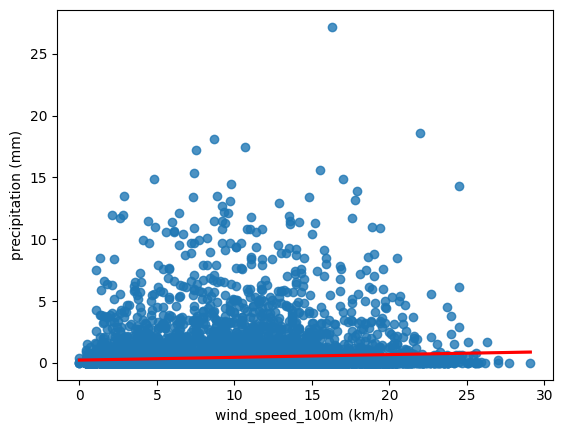

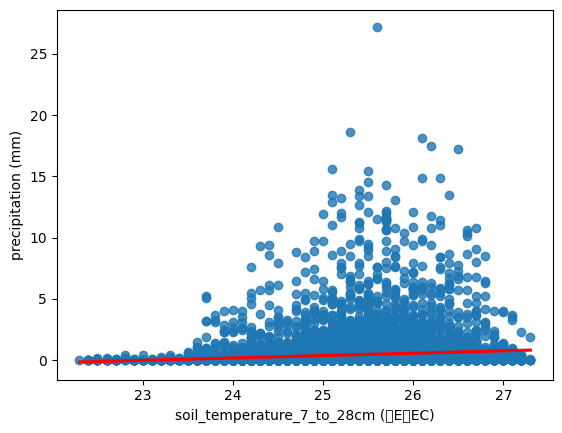

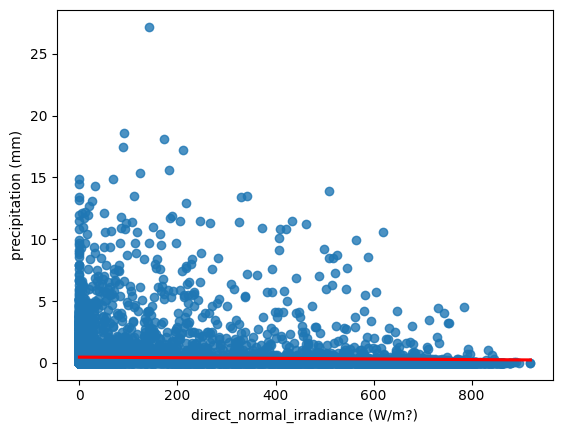

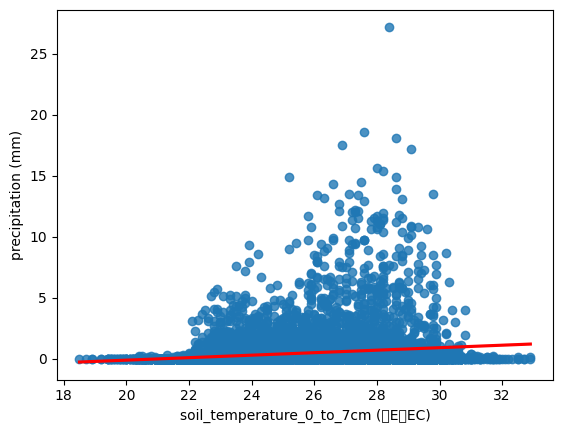

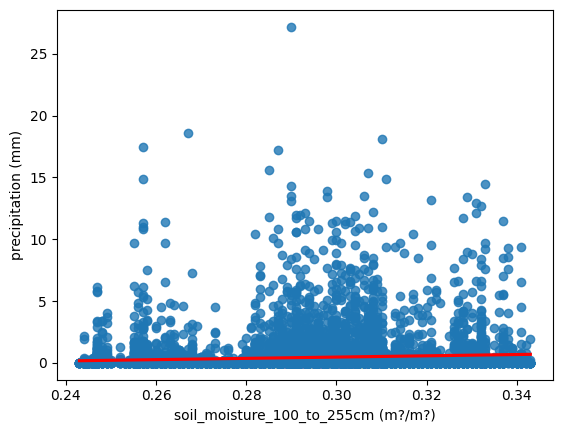

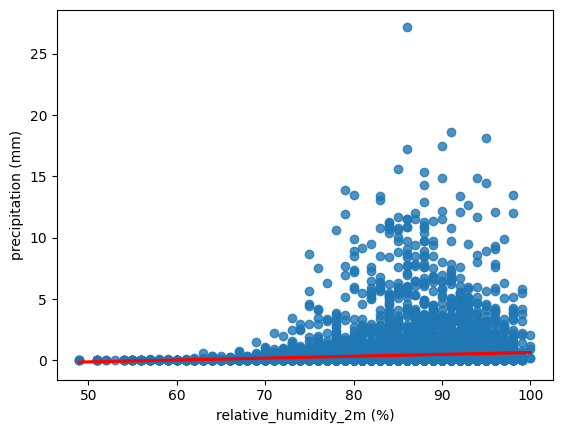

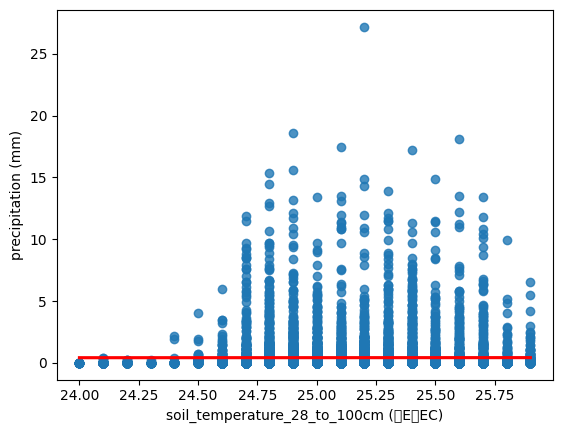

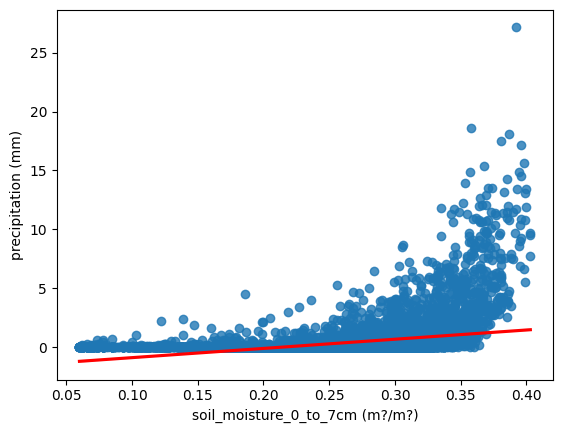

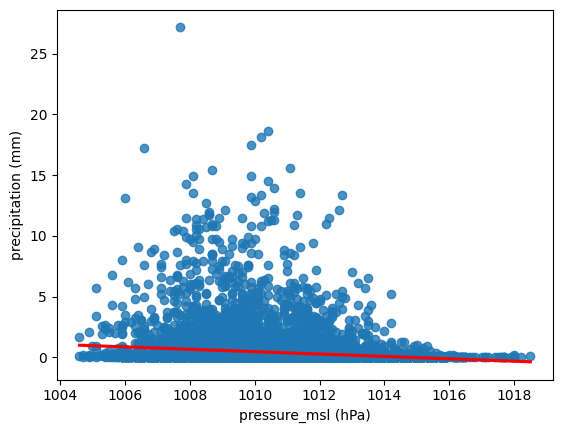

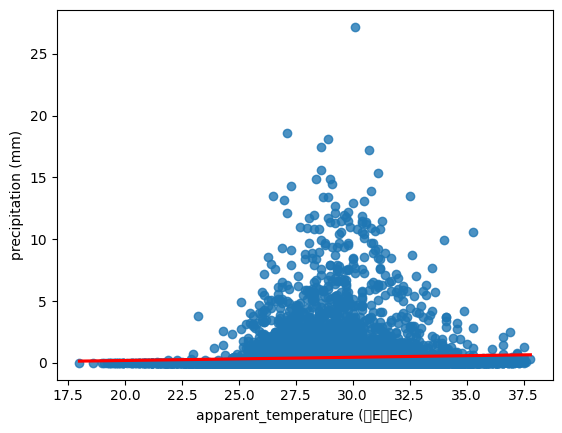

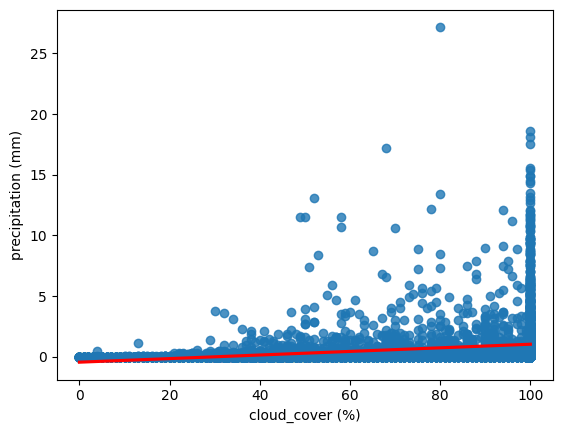

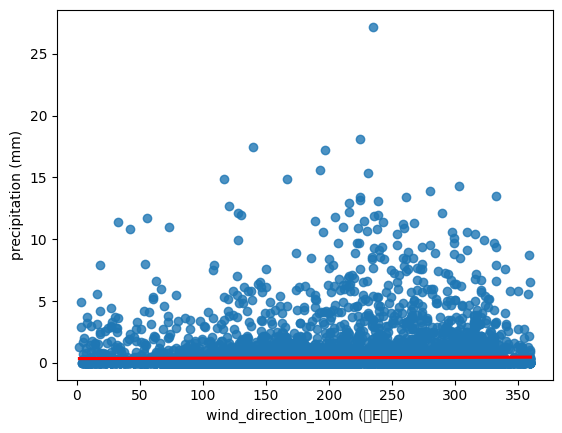

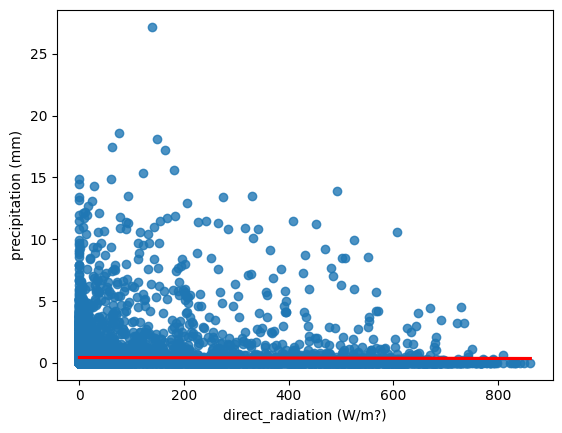

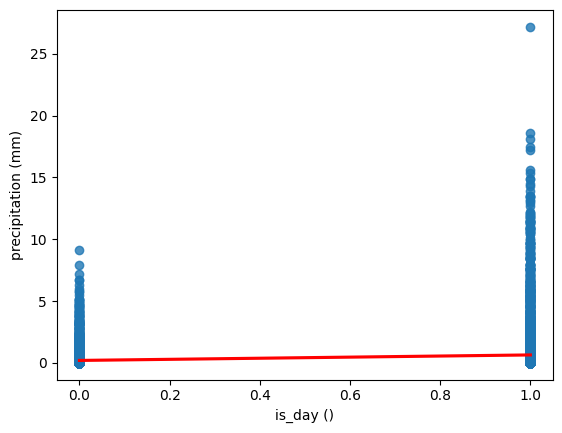

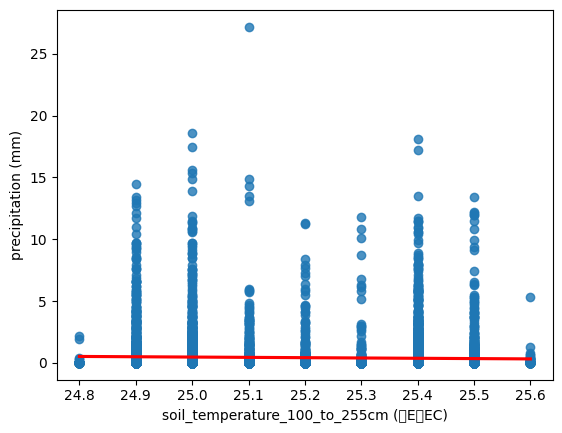

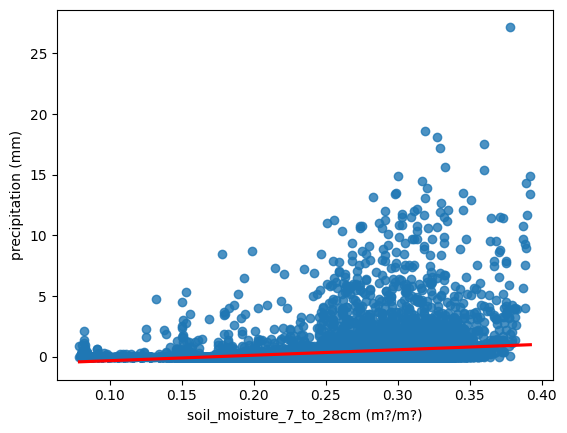

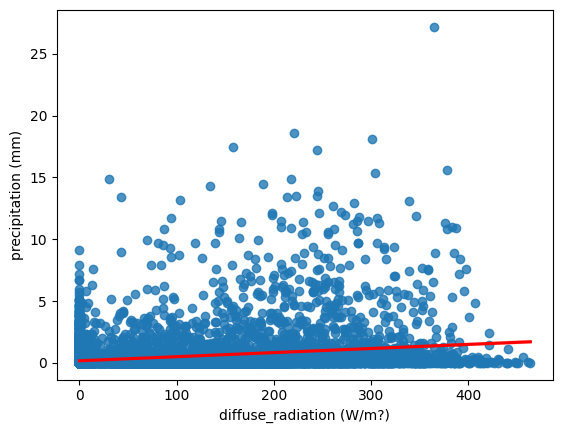

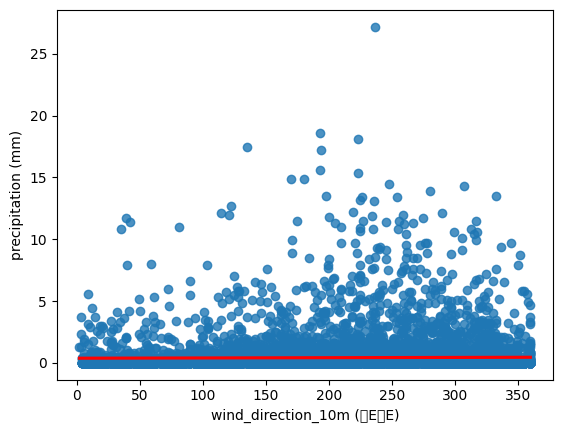

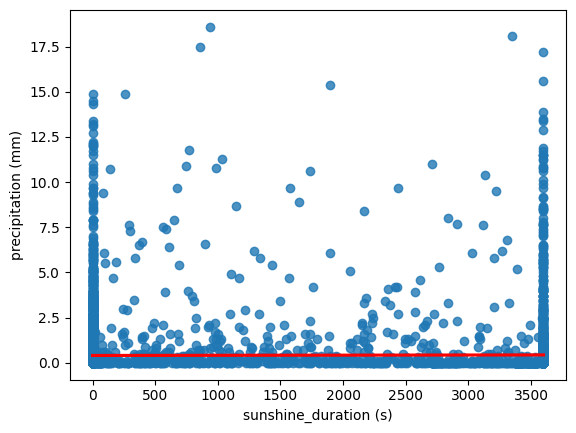

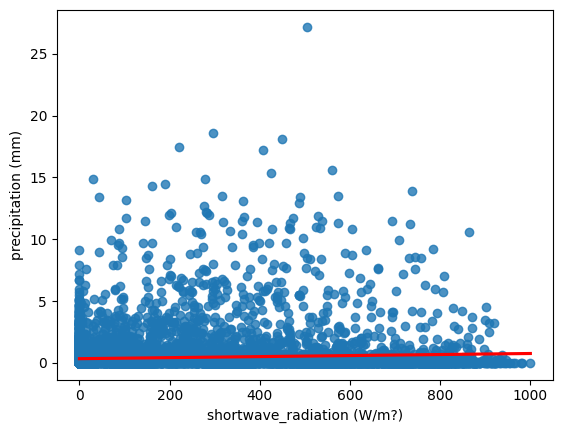

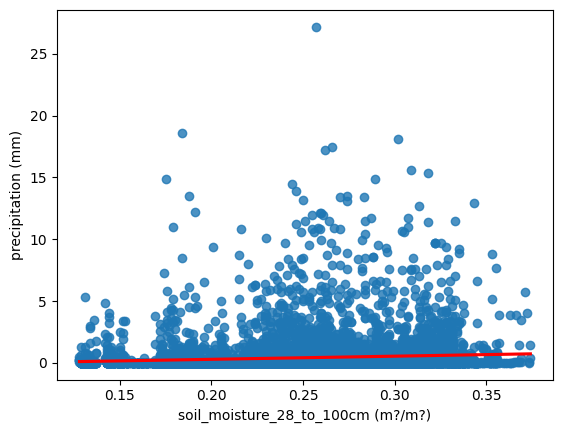

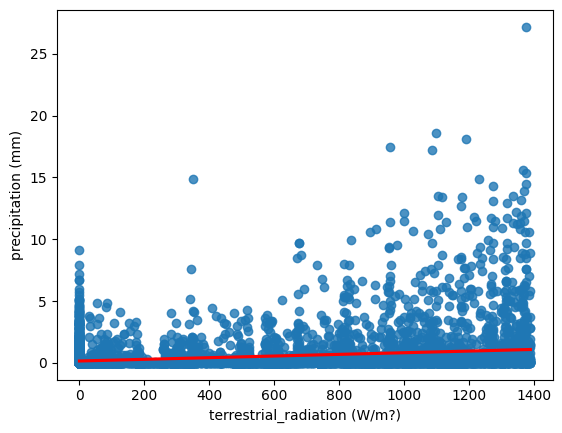

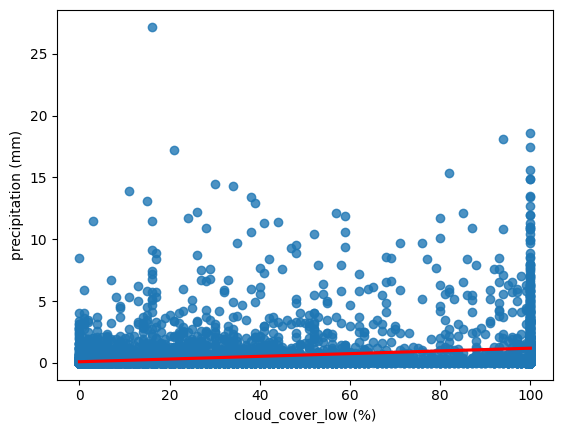

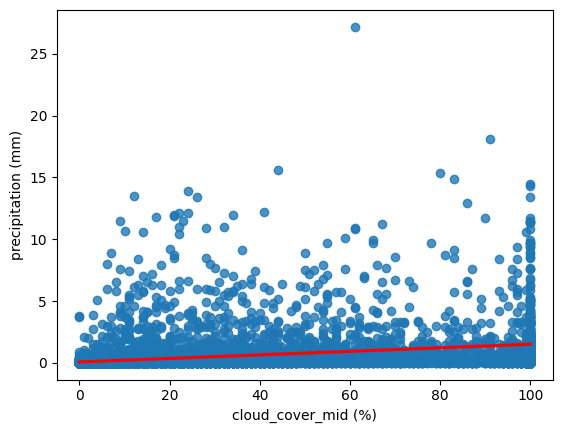

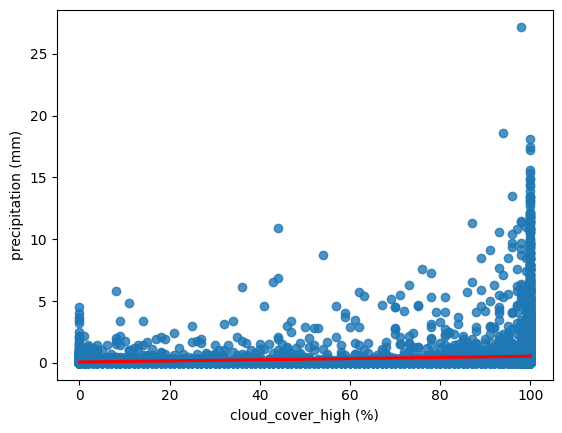

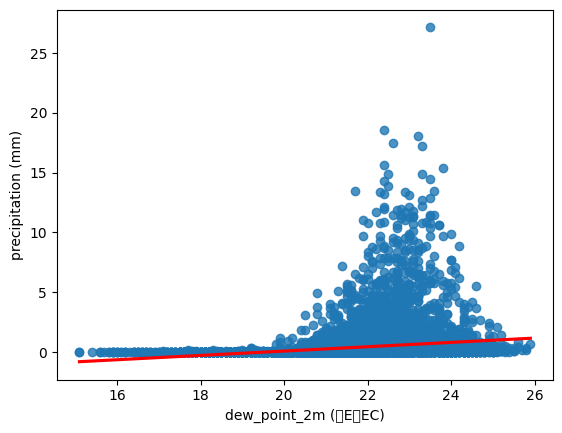

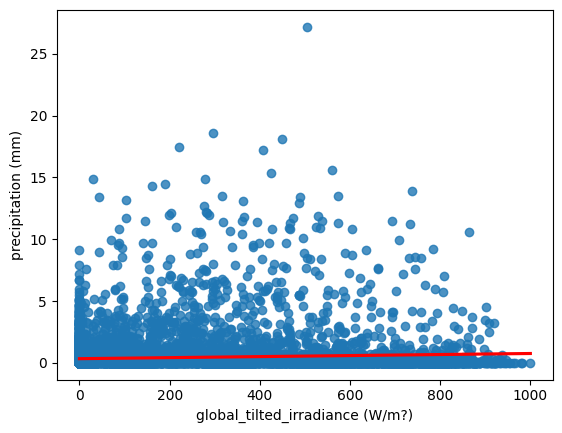

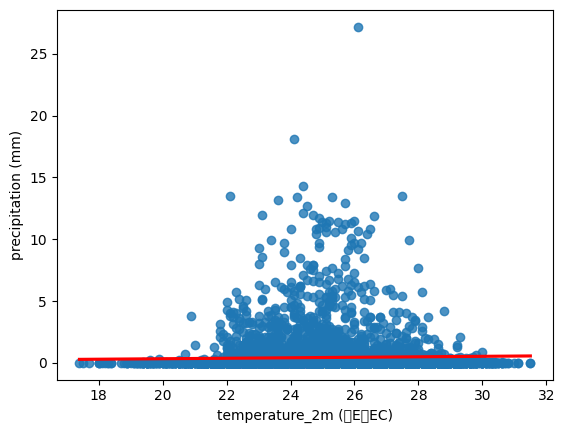

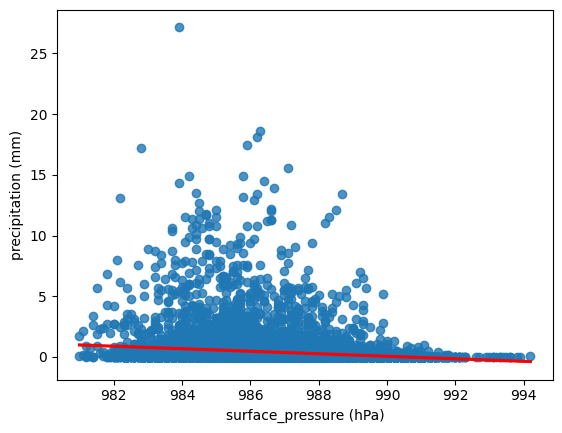

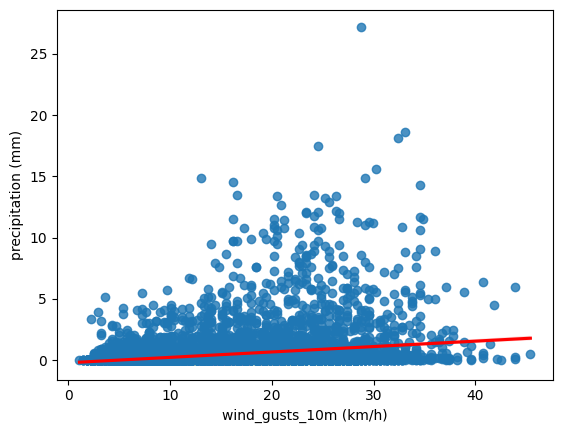

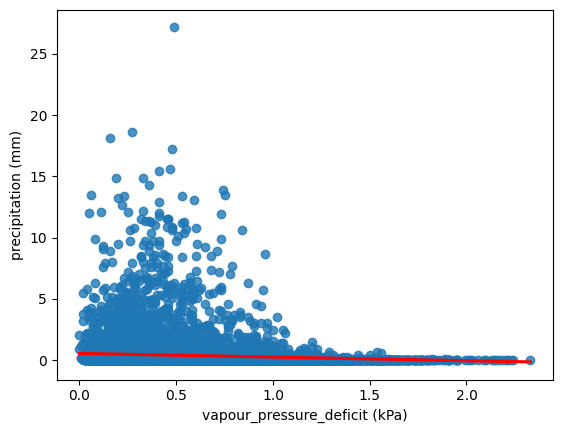

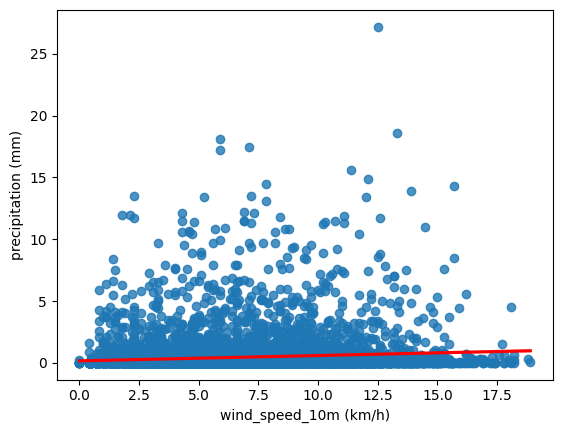

In [ ]:
for col in used_cols:
    sns.regplot(data=train_df, x=col, y="precipitation (mm)", line_kws=dict(color="r"))
    plt.xlabel(col)
    plt.ylabel("precipitation (mm)")
    plt.show()

Berdasarkan grafik-grafik regplot di atas, tidak ada fitur yang menunjukkan hubungan linearitas yang kuat dengan fitur "precipitation (mm)". Gradien tiap grafik cenderung datar dan sangat kecil (mendekati 0). Ini berarti model regressi yang mengandalkan hubungan linear, seperti Linear Regression tidak akan bekerja dengan baik dalam memprediksi "precipitation (mm)". Dengan begitu, model-model non linear seperti Decision Tree, Random Forest, XGBoost, ataupun KNeighbors seharusnya memberikan hasil yang lebih baik.

### Pertanyaan 2

Apakah ada korelasi yang kuat atau multikolinearitas di antara fitur-fitur independen itu sendiri?

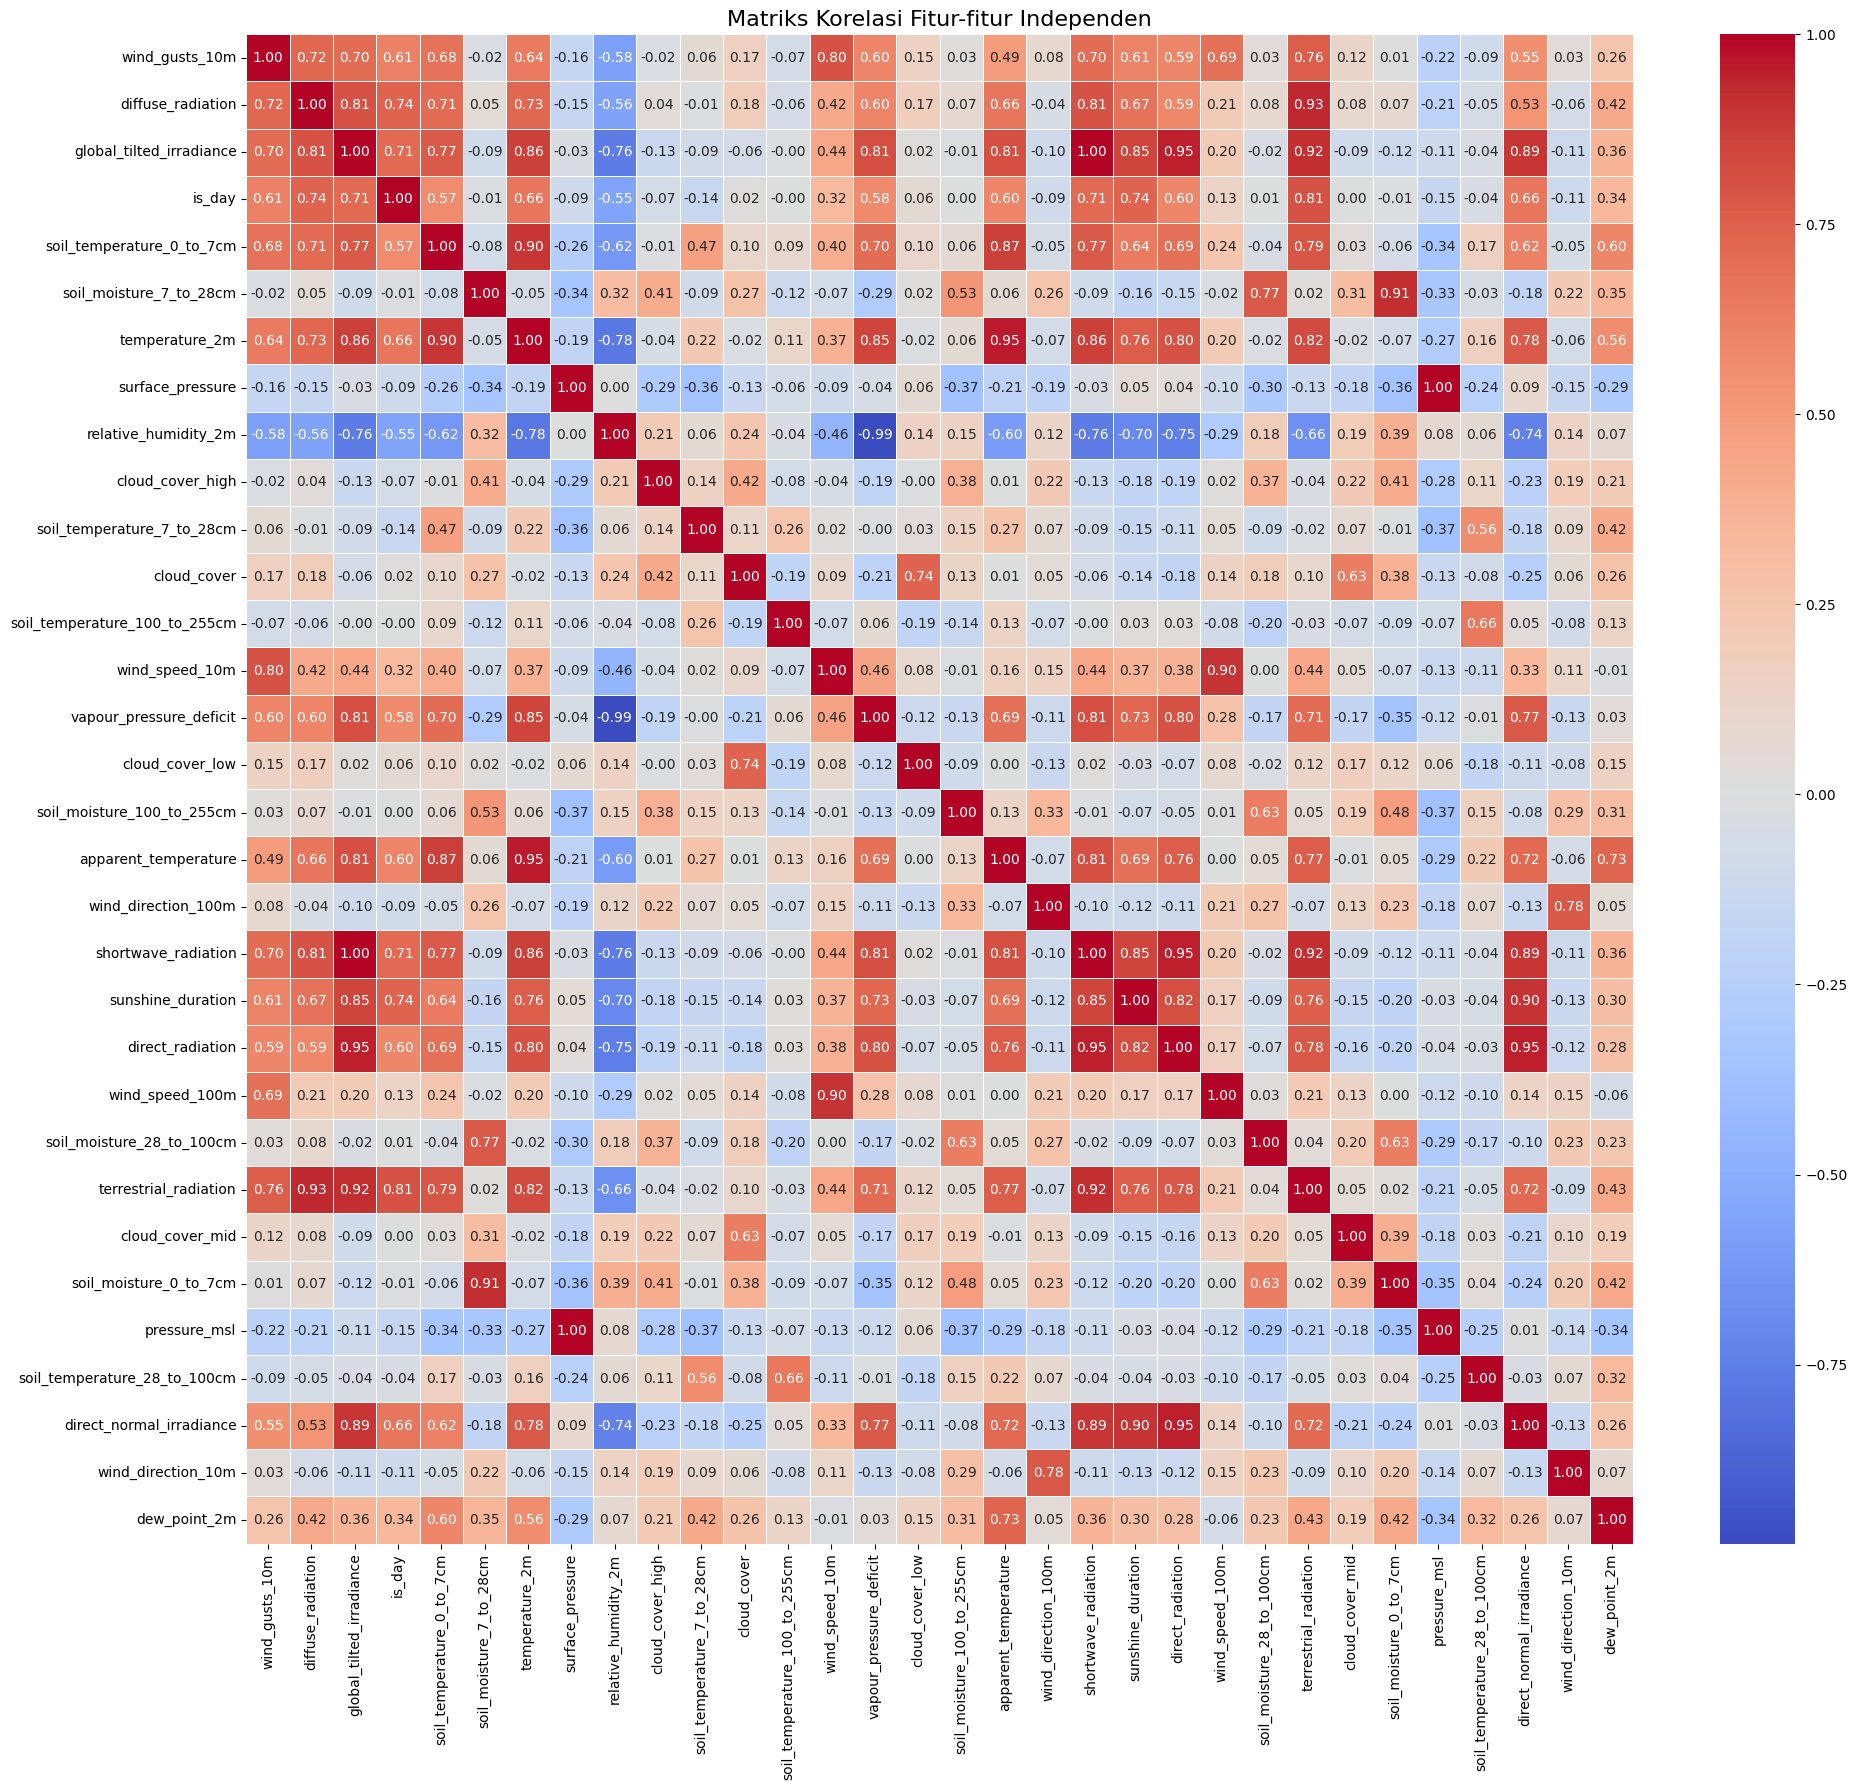

In [ ]:
import re

def clean_col_name(col_name):
    return re.sub(r'\s*\([^)]*\)', '', col_name).strip()

independent_features_df = train_df[used_cols].copy()

correlation_matrix = independent_features_df.corr()

correlation_matrix.columns = [clean_col_name(col) for col in correlation_matrix.columns]
correlation_matrix.index = [clean_col_name(idx) for idx in correlation_matrix.index]

plt.figure(figsize=(20, 18))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriks Korelasi Fitur-fitur Independen', fontsize=16)
plt.xticks(rotation=90, fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()


Dari heatmap matriks korelasi di atas, kita dapat mengidentifikasi beberapa hal terkait multikolinearitas dan hubungan antar fitur:

1.  **Korelasi Positif Kuat:** Warna merah cerah menunjukkan korelasi positif yang kuat. Ini berarti ketika nilai satu fitur meningkat, nilai fitur lainnya juga cenderung meningkat.
    *   Contohnya, `temperature_2m` dan `apparent_temperature` kemungkinan besar memiliki korelasi yang sangat tinggi. Demikian juga `dew_point_2m`.
    *   Beberapa fitur radiasi (`shortwave_radiation`, `direct_radiation`, `diffuse_radiation`, `global_tilted_irradiance`, `direct_normal_irradiance`) seringkali sangat berkorelasi satu sama lain karena mengukur aspek yang serupa dari radiasi matahari.

2.  **Korelasi Negatif Kuat:** Warna biru tua menunjukkan korelasi negatif yang kuat. Ini berarti ketika nilai satu fitur meningkat, nilai fitur lainnya cenderung menurun.
    *   Perhatikan apakah ada fitur yang memiliki korelasi negatif kuat dengan fitur lain.

3.  **Multikolinearitas Tinggi:** Pasangan fitur dengan nilai korelasi absolut mendekati 1 (misalnya, > 0.8 atau > 0.9) mengindikasikan adanya multikolinearitas yang tinggi.

### Pertanyaan 3

Fitur mana yang berkorelasi dengan precipitation (mm)?

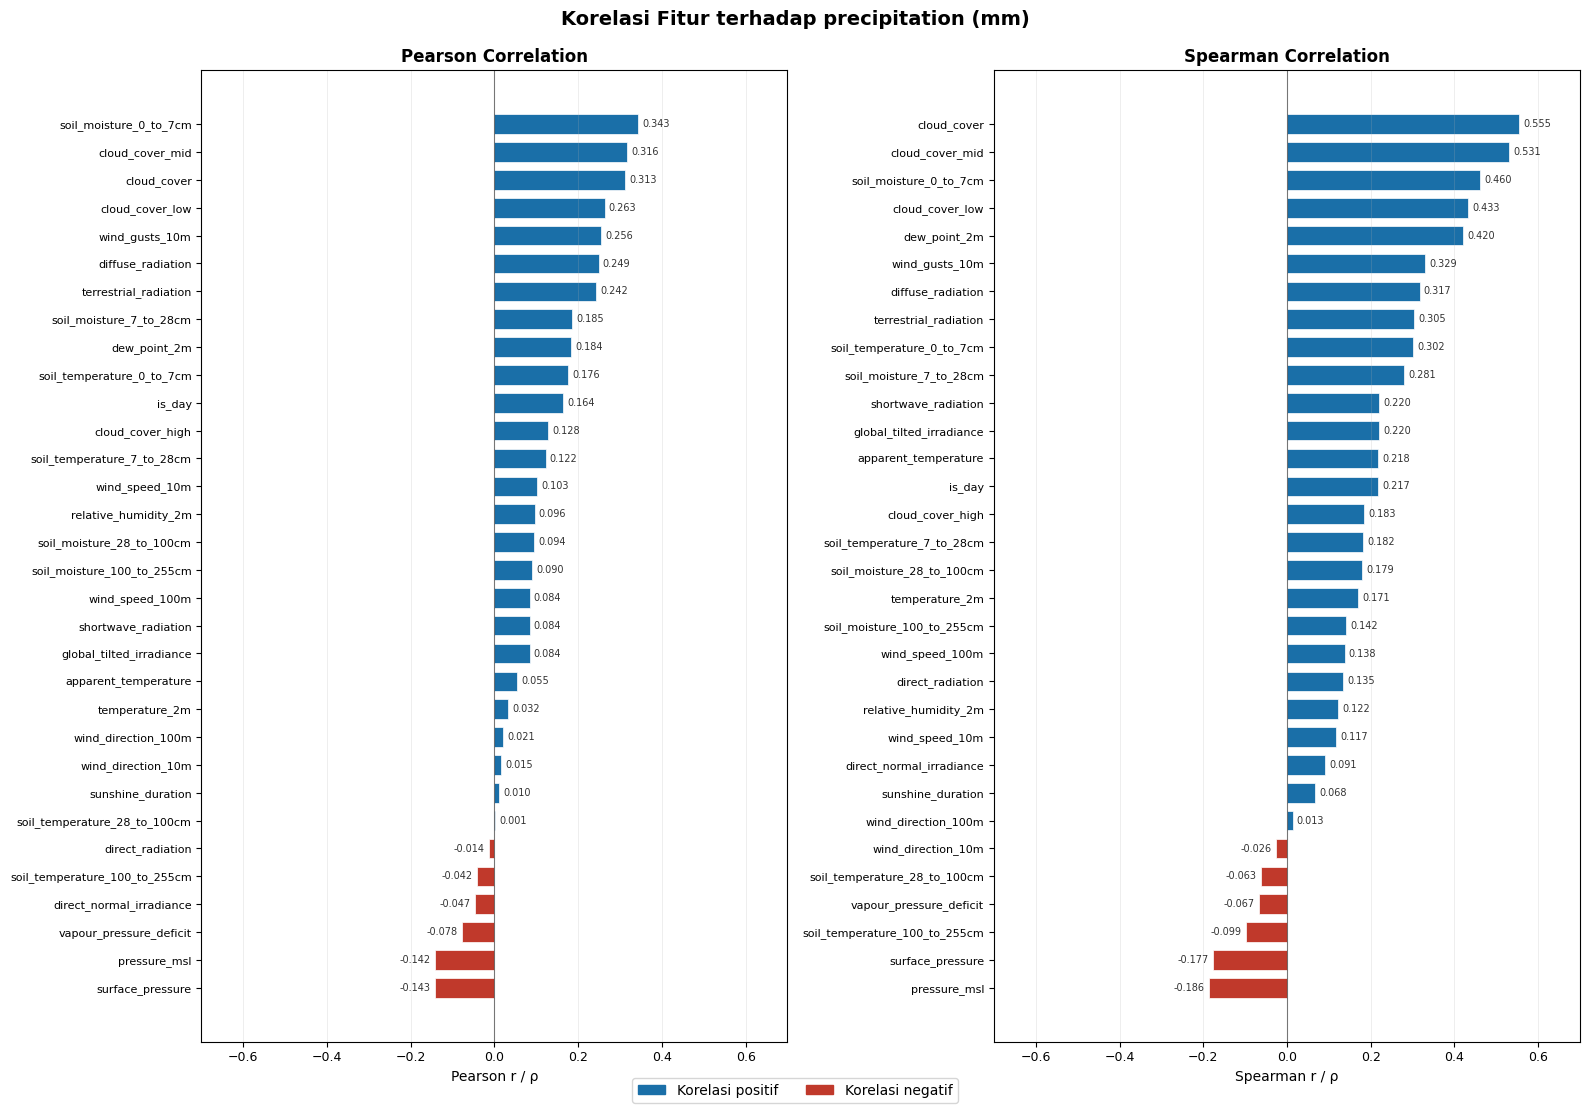


Kesimpulan:
  - Fitur terkuat: cloud_cover (ρ=0.5549)
  - Kelompok cloud cover, soil moisture, dew point = prediktor utama
  - surface_pressure & pressure_msl berkorelasi negatif (ρ≈-0.18)
  - Spearman > Pearson menunjukkan hubungan non-linear — pertimbangkan tree-based model


In [ ]:
prec_col = 'precipitation (mm)'


numeric_cols = train_df.select_dtypes(include=[np.number]).columns.tolist()
feat_cols = [c for c in numeric_cols if c not in ['ID', 'electricity_shutdown', prec_col]]

pearson_corr = train_df[feat_cols + [prec_col]].corr()[prec_col].drop(prec_col)
spearman_corr = train_df[feat_cols + [prec_col]].corr(method='spearman')[prec_col].drop(prec_col)

import re
def clean_label(s):
    return re.sub(r'\s*[\(\[].*?[\)\]]', '', s).strip()

corr_df = pd.DataFrame({
    'feature': feat_cols,
    'label': [clean_label(c) for c in feat_cols],
    'pearson': pearson_corr.values,
    'spearman': spearman_corr.values
}).sort_values('spearman', ascending=False).reset_index(drop=True)


fig, axes = plt.subplots(1, 2, figsize=(16, 11))
fig.suptitle('Korelasi Fitur terhadap precipitation (mm)',
             fontsize=14, fontweight='bold', y=0.99)

for ax, method, col in zip(axes, ['Pearson', 'Spearman'], ['pearson', 'spearman']):
    sorted_df = corr_df.sort_values(col, ascending=True)
    colors = ['#c0392b' if v < 0 else '#1a6fa8' for v in sorted_df[col]]
    bars = ax.barh(sorted_df['label'], sorted_df[col], color=colors,
                   edgecolor='white', linewidth=0.5, height=0.7)
    ax.axvline(0, color='black', linewidth=0.8, alpha=0.5)
    ax.set_title(f'{method} Correlation', fontsize=12, fontweight='bold')
    ax.set_xlabel(f'{method} r / ρ', fontsize=10)
    ax.tick_params(axis='y', labelsize=8)
    ax.tick_params(axis='x', labelsize=9)
    ax.set_xlim(-0.7, 0.7)
    ax.grid(axis='x', alpha=0.3, linewidth=0.5)

    for bar, v in zip(bars, sorted_df[col]):
        xpos = v + 0.01 if v >= 0 else v - 0.01
        ha = 'left' if v >= 0 else 'right'
        ax.text(xpos, bar.get_y() + bar.get_height()/2,
                f'{v:.3f}', va='center', ha=ha, fontsize=7, color='#333')


pos_patch = mpatches.Patch(color='#1a6fa8', label='Korelasi positif')
neg_patch = mpatches.Patch(color='#c0392b', label='Korelasi negatif')
fig.legend(handles=[pos_patch, neg_patch], loc='lower center',
           ncol=2, fontsize=10, bbox_to_anchor=(0.5, -0.01))

plt.tight_layout()
plt.savefig('eda_q6_feature_correlation.png', dpi=150, bbox_inches='tight')
plt.show()


print('\nKesimpulan:')
print(f"  - Fitur terkuat: {corr_df.iloc[0]['label']} (ρ={corr_df.iloc[0]['spearman']:.4f})")
print(f"  - Kelompok cloud cover, soil moisture, dew point = prediktor utama")
print(f"  - surface_pressure & pressure_msl berkorelasi negatif (ρ≈-0.18)")
print(f"  - Spearman > Pearson menunjukkan hubungan non-linear — pertimbangkan tree-based model")


### Pertanyaan 4

Bagaimana dampak fitur beberapa jam yang lalu terhadap presipitasi saat ini?

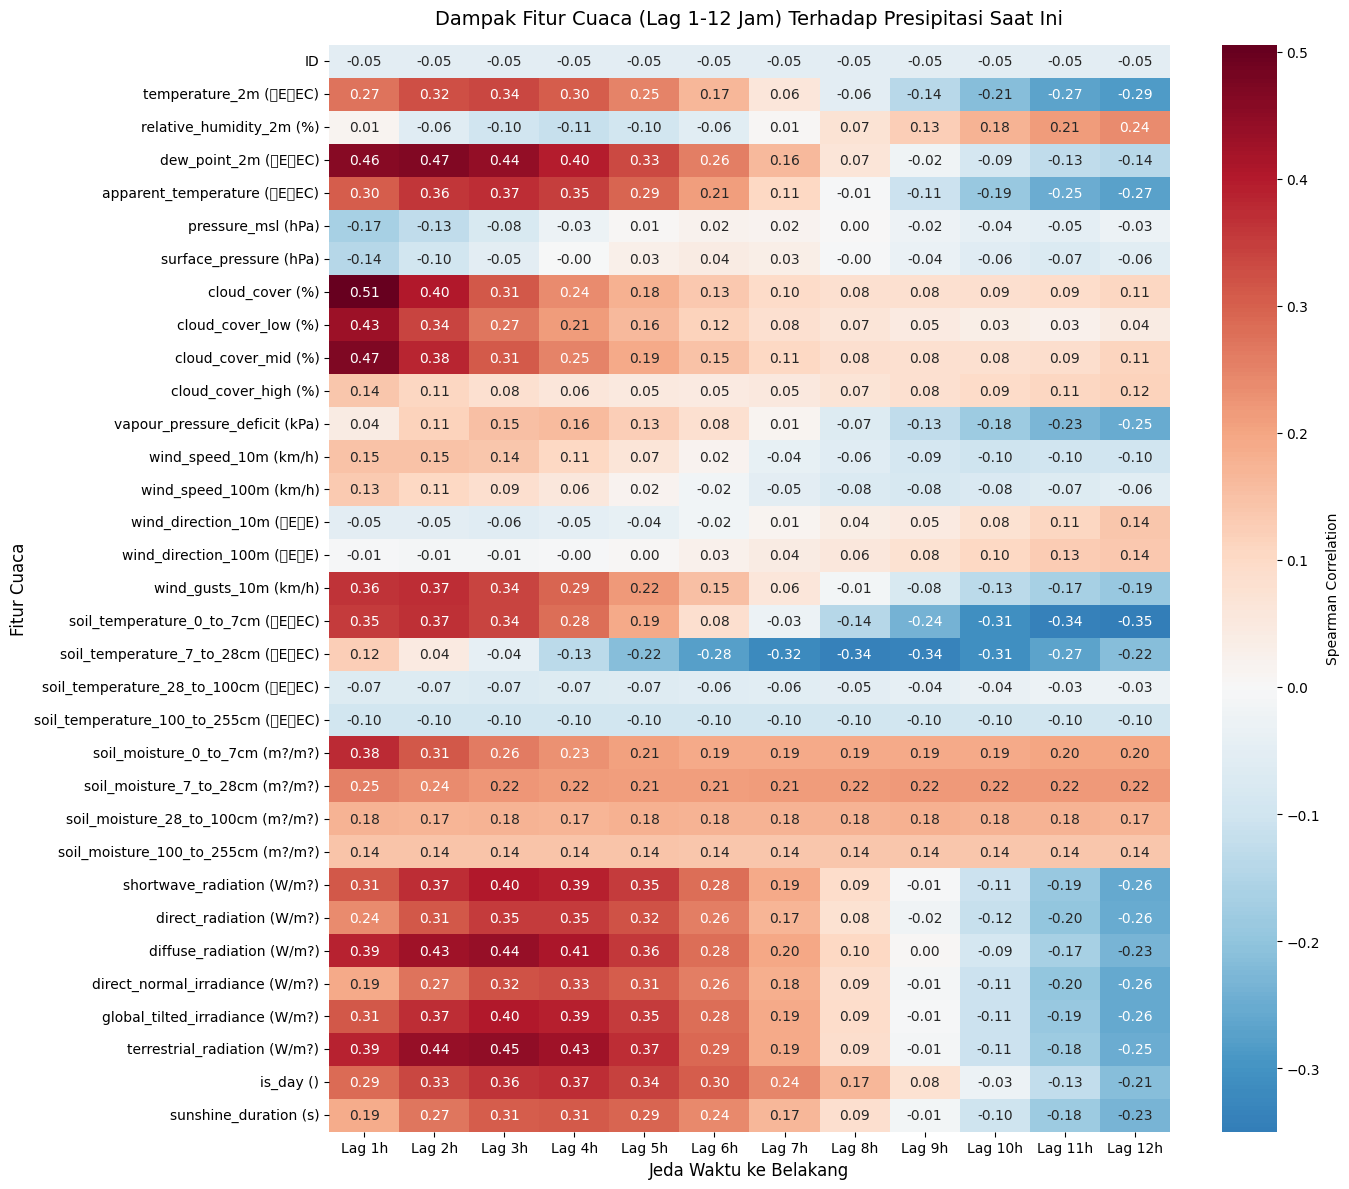

In [ ]:
target_col = 'precipitation (mm)'

features = train_df.select_dtypes(include=[np.number]).columns.drop([target_col, 'electricity_shutdown'])

lags = range(1, 13)

lag_corr_results = {}

for feature in features:
    feature_corrs = []
    for lag in lags:
        corr = train_df[target_col].corr(train_df[feature].shift(lag), method='spearman')
        feature_corrs.append(corr)
    lag_corr_results[feature] = feature_corrs

lag_corr_df = pd.DataFrame(lag_corr_results, index=[f'Lag {i}h' for i in lags]).T

plt.figure(figsize=(14, 12))
sns.heatmap(lag_corr_df,
            annot=True,
            fmt=".2f",
            cmap='RdBu_r',
            center=0,
            cbar_kws={'label': 'Spearman Correlation'})

plt.title('Dampak Fitur Cuaca (Lag 1-12 Jam) Terhadap Presipitasi Saat Ini', fontsize=14, pad=15)
plt.xlabel('Jeda Waktu ke Belakang', fontsize=12)
plt.ylabel('Fitur Cuaca', fontsize=12)
plt.tight_layout()
plt.show()

### Pertanyaan 5
Bagaimana distribusi dan statistik deskriptif fitur precipitation (mm)?


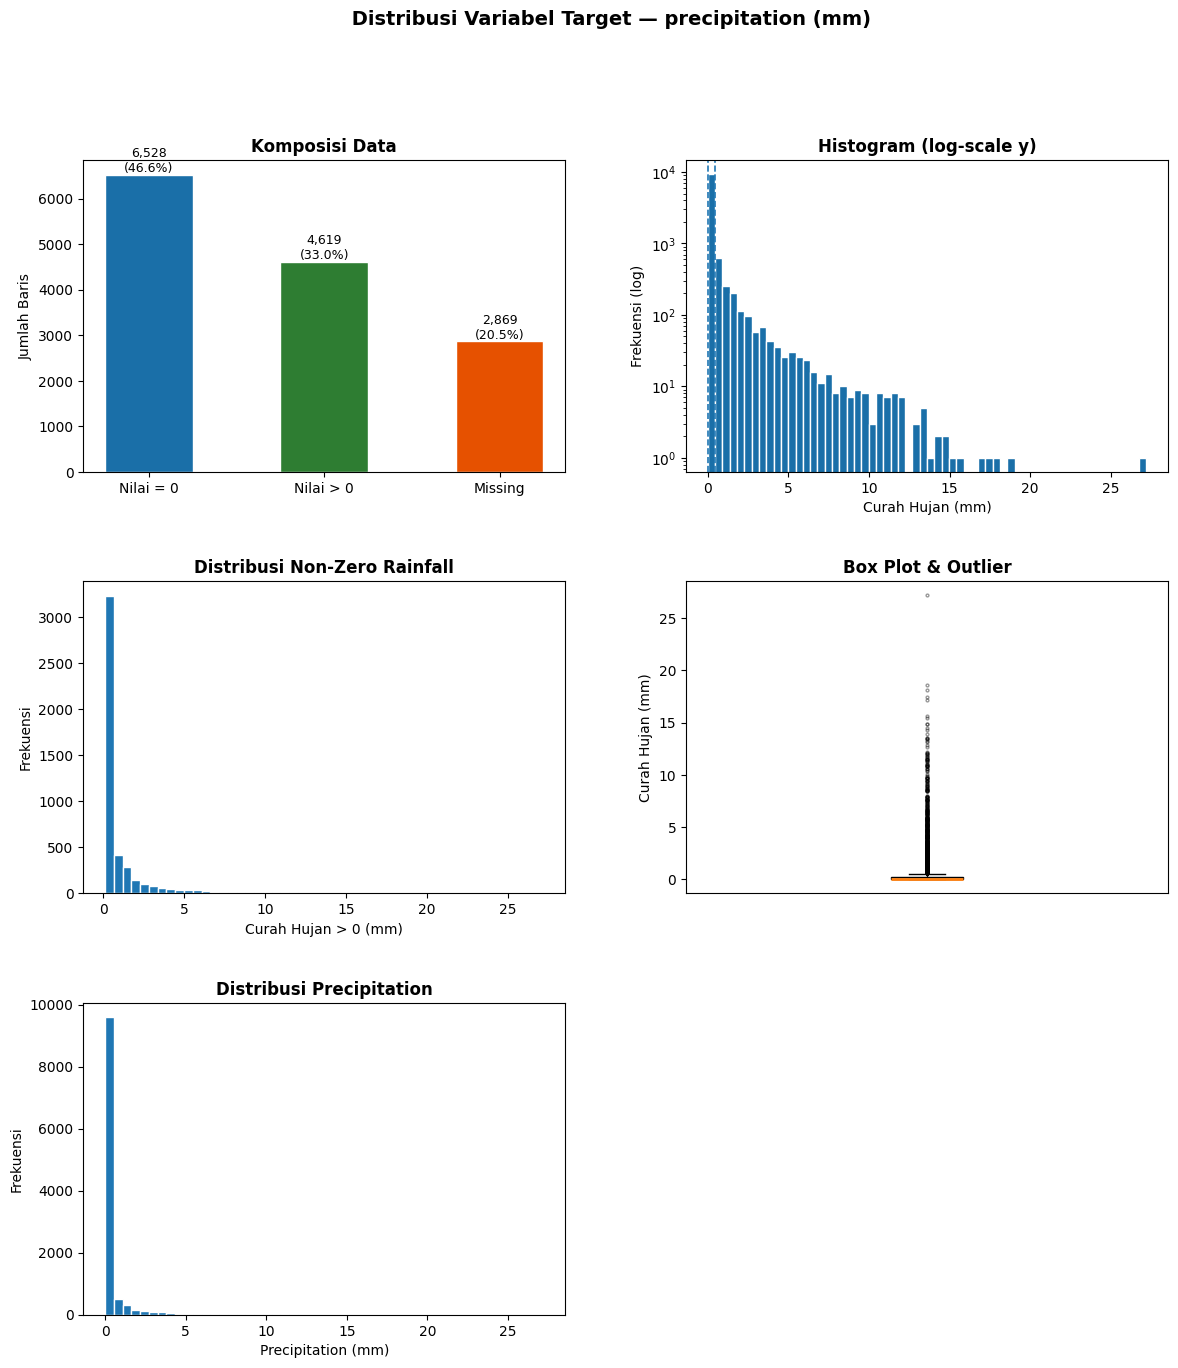

In [ ]:
prec_col = 'precipitation (mm)'
prec = train_df[prec_col].dropna()


total = len(train_df)
valid = len(prec)
n_zero = (prec == 0).sum()
n_missing = train_df[prec_col].isna().sum()
pct_zero = n_zero / valid * 100
pct_missing = n_missing / total * 100

fig = plt.figure(figsize=(14, 15))
fig.suptitle(' Distribusi Variabel Target — precipitation (mm)',
             fontsize=14, fontweight='bold')

gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.35, wspace=0.25)

# Panel 1: Komposisi data
ax1 = fig.add_subplot(gs[0, 0])
categories = ['Nilai = 0', 'Nilai > 0', 'Missing']
vals = [n_zero, (prec>0).sum(), n_missing]
colors_bar = ['#1a6fa8', '#2e7d32', '#e65100']

bars = ax1.bar(categories, vals, color=colors_bar, width=0.5, edgecolor='white')
for bar, v in zip(bars, vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
             f'{v:,}\n({v/total*100:.1f}%)',
             ha='center', va='bottom', fontsize=9)

ax1.set_title('Komposisi Data', fontweight='bold')
ax1.set_ylabel('Jumlah Baris')

# Panel 2: Histogram
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(prec, bins=60, color='#1a6fa8', edgecolor='white', log=True)

ax2.axvline(prec.mean(), linestyle='--', linewidth=1.2)
ax2.axvline(prec.median(), linestyle='--', linewidth=1.2)

ax2.set_title('Histogram (log-scale y)', fontweight='bold')
ax2.set_xlabel('Curah Hujan (mm)')
ax2.set_ylabel('Frekuensi (log)')

# Panel 3: Histogram non-zero (biar lebih informatif)
ax3 = fig.add_subplot(gs[1, 0])
prec_nonzero = prec[prec > 0]

ax3.hist(prec_nonzero, bins=50, edgecolor='white')
ax3.set_title('Distribusi Non-Zero Rainfall', fontweight='bold')
ax3.set_xlabel('Curah Hujan > 0 (mm)')
ax3.set_ylabel('Frekuensi')

# Panel 4: Boxplot
ax4 = fig.add_subplot(gs[1, 1])
ax4.boxplot(prec, vert=True, patch_artist=True,
            boxprops=dict(facecolor='#e3f2fd'),
            medianprops=dict(linewidth=2),
            flierprops=dict(marker='o', markersize=2, alpha=0.4))

ax4.set_title('Box Plot & Outlier', fontweight='bold')
ax4.set_ylabel('Curah Hujan (mm)')
ax4.set_xticks([])

# Panel 5: Histogram
ax5 = fig.add_subplot(gs[2, 0])
prec_nonzero = prec[prec >= 0]

ax5.hist(prec_nonzero, bins=50, edgecolor='white')
ax5.set_title('Distribusi Precipitation', fontweight='bold')
ax5.set_xlabel('Precipitation (mm)')
ax5.set_ylabel('Frekuensi')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('eda_q5_precipitation_distribution.png', dpi=150)
plt.show()

Decission Tree - Dion
---

In [ ]:
df_reg = train_df.copy()

# Konversi waktu
df_reg['time'] = pd.to_datetime(df_reg['time'])

# Sort berdasarkan waktu (penting untuk rolling/lag features)
df_reg = df_reg.sort_values('time').reset_index(drop=True)

# Drop baris yang targetnya (Precipitation) kosong (jika ada)
df_reg = df_reg.dropna(subset=['precipitation (mm)'])

# --- 2. Feature Engineering (Disesuaikan) ---
# Temporal Features
df_reg['hour'] = df_reg['time'].dt.hour
df_reg['month'] = df_reg['time'].dt.month

# Cyclical Encoding
df_reg['hour_sin'] = np.sin(2*np.pi*df_reg['hour']/24)
df_reg['hour_cos'] = np.cos(2*np.pi*df_reg['hour']/24)
df_reg['month_sin'] = np.sin(2*np.pi*df_reg['month']/12)
df_reg['month_cos'] = np.cos(2*np.pi*df_reg['month']/12)

# Fitur Interaksi & Cuaca (Sama seperti sebelumnya)
df_reg['wind_rolling_6h'] = df_reg['wind_speed_10m (km/h)'].rolling(6, min_periods=1).mean()
df_reg['pressure_drop_3h'] = df_reg['surface_pressure (hPa)'].diff(3).fillna(0)
# Perhatikan: pastikan nama kolom temperatur sesuai dengan di datasetmu (tadi ada karakter aneh E..C)
df_reg['humid_heat'] = df_reg['temperature_2m (\x81E\x81EC)'] * df_reg['relative_humidity_2m (%)']
df_reg['cloud_humidity_index'] = df_reg['cloud_cover (%)'] * df_reg['relative_humidity_2m (%)']
df_reg['wind_gust_ratio'] = df_reg['wind_gusts_10m (km/h)'] / (df_reg['wind_speed_10m (km/h)'] + 1e-5)
df_reg['pressure_diff'] = df_reg['pressure_msl (hPa)'] - df_reg['surface_pressure (hPa)']

# --- 3. Pemisahan X dan y ---
# Target sekarang adalah precipitation
y_precip = df_reg['precipitation (mm)']

# Fitur adalah semua kolom KECUALI target, time, ID, dan electricity_shutdown (opsional)
# Kita drop electricity_shutdown agar tidak terjadi kebocoran data jika itu adalah label masa depan
cols_to_drop = ['time', 'precipitation (mm)', 'ID', 'electricity_shutdown']
X_precip = df_reg.drop(columns=[c for c in cols_to_drop if c in df_reg.columns])

# # --- 4. Train-Val Split (Tanpa Stratify) ---
# X_train_p, X_val_p, y_train_p, y_val_p = train_test_split(
#     X_precip, y_precip,
#     test_size=0.2,
#     random_state=SEED
#     # Jangan pakai stratify=y karena ini regresi
# )

X = X_precip
y = y_precip

In [ ]:
# HASIL HYPERPARAMETER TUNING
#Best Params: {'max_depth': 13, 'min_samples_split': 17, 'min_samples_leaf': 4, 'max_features': None, 'criterion': 'friedman_mse', 'min_impurity_decrease': 0.04530176467112996, 'ccp_alpha': 0.0002446782441288507}

model_tree = DecisionTreeRegressor(
    random_state=SEED,
    max_depth=13,
    min_samples_split=17,
    min_samples_leaf=4,
    max_features=None,
    criterion='friedman_mse',
    min_impurity_decrease=0.0453017646711299,
    ccp_alpha=0.0002446782441288507
)

cv_tree = KFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED
)

sfs_tree = SequentialFeatureSelector(estimator=model_tree,
                                     n_features_to_select=5,
                                     direction='forward',
                                     scoring='r2',
                                     cv=cv_tree, n_jobs=-1)

tree_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ('imputer', KNNImputer()),
    ("sfs", sfs_tree),
    ("model", model_tree),
])

scores_tree = cross_val_score(
    tree_pipeline,
    X,
    y,
    scoring="r2",
    cv=cv_tree,
    n_jobs=-1,
)

tree_pipeline.fit(X, y)

print("r2 per fold:", scores_tree)
print("mean r2:", scores_tree.mean())

Decision Tree Hyperparameter Tuning (uncomment buat run)

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

cv = KFold(n_splits=4, shuffle=True, random_state=SEED)

def objective(trial):
    # Hyperparameter search space
    params = {
        "max_depth":            trial.suggest_int("max_depth", 2, 20),
        "min_samples_split":    trial.suggest_int("min_samples_split", 2, 50),
        "min_samples_leaf":     trial.suggest_int("min_samples_leaf", 1, 30),
        "max_features":         trial.suggest_categorical("max_features", ["sqrt", "log2", None]),
        "criterion":            trial.suggest_categorical("criterion", ["squared_error", "friedman_mse", "absolute_error"]),
        "min_impurity_decrease":trial.suggest_float("min_impurity_decrease", 0.0, 0.1),
        "ccp_alpha":            trial.suggest_float("ccp_alpha", 0.0, 0.05),
    }

    model = DecisionTreeRegressor(random_state=SEED, **params)

    sfs = SequentialFeatureSelector(
        estimator=model,
        n_features_to_select=5,
        direction='forward',
        scoring='r2',
        cv=cv,
        n_jobs=-1
    )

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("imputer", KNNImputer()),
        ("sfs", sfs),
        ("model", model),
    ])

    scores = cross_val_score(pipeline, X, y, scoring="r2", cv=cv, n_jobs=-1)
    return scores.mean()


study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEED),
    study_name="DecisionTree_Tuning"
)

study.optimize(objective, n_trials=30, show_progress_bar=True)

# ── Hasil ──────────────────────────────────────────────────────────────
print("=" * 50)
print(f"Best R²   : {study.best_value:.4f}")
print(f"Best Params: {study.best_params}")

# ── Retrain dengan best params ─────────────────────────────────────────
best_model = DecisionTreeRegressor(random_state=SEED, **study.best_params)

best_sfs = SequentialFeatureSelector(
    estimator=best_model,
    n_features_to_select=5,
    direction='forward',
    scoring='r2',
    cv=cv,
    n_jobs=-1
)

best_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("imputer", KNNImputer()),
    ("sfs", best_sfs),
    ("model", best_model),
])

scores_best = cross_val_score(best_pipeline, X, y, scoring="r2", cv=cv, n_jobs=-1)
print(f"\nCV R² per fold : {scores_best}")
print(f"Mean R²        : {scores_best.mean():.4f}")

best_pipeline.fit(X, y)

In [ ]:
# Copy data test asli
test_reg = test_df.copy()
test_reg['time'] = pd.to_datetime(test_reg['time'])

# Feature Engineering
test_reg['hour'] = test_reg['time'].dt.hour
test_reg['month'] = test_reg['time'].dt.month

# Cyclical Encoding
test_reg['hour_sin'] = np.sin(2*np.pi*test_reg['hour']/24)
test_reg['hour_cos'] = np.cos(2*np.pi*test_reg['hour']/24)
test_reg['month_sin'] = np.sin(2*np.pi*test_reg['month']/12)
test_reg['month_cos'] = np.cos(2*np.pi*test_reg['month']/12)

# Weather Features
test_reg['wind_rolling_6h'] = test_reg['wind_speed_10m (km/h)'].rolling(6, min_periods=1).mean()
test_reg['pressure_drop_3h'] = test_reg['surface_pressure (hPa)'].diff(3).fillna(0)
test_reg['humid_heat'] = test_reg['temperature_2m (\x81E\x81EC)'] * test_reg['relative_humidity_2m (%)']
test_reg['cloud_humidity_index'] = test_reg['cloud_cover (%)'] * test_reg['relative_humidity_2m (%)']
test_reg['wind_gust_ratio'] = test_reg['wind_gusts_10m (km/h)'] / (test_reg['wind_speed_10m (km/h)'] + 1e-5)
test_reg['pressure_diff'] = test_reg['pressure_msl (hPa)'] - test_reg['surface_pressure (hPa)']

# Drop kolom yang tidak digunakan sebagai fitur
X_test_final = test_reg.drop(columns=['time', 'ID', 'precipitation (mm)', 'electricity_shutdown'], errors='ignore')

# Pastikan urutan kolom X_test sama dengan X_train
X_test_final = X_test_final[X.columns]

# Predict
y_pred_test_reg = tree_pipeline.predict(X_test_final)

# Pastikan tidak ada nilai negatif
y_pred_test_reg = np.clip(y_pred_test_reg, a_min=0, a_max=None)

# Create Submission DataFrame
submission_reg = pd.DataFrame({
    'ID': test_df['ID'],
    'precipitation (mm)': y_pred_test_reg
})

# Menampilkan hasil
display(submission_reg.head())

# Save to CSV
submission_reg.to_csv('submission_tree.csv', index=False)
print("File 'submission_tree.csv' berhasil dibuat!")

# Random Forest - Raihan

In [ ]:
df_reg = train_df.copy()

# Konversi waktu
df_reg['time'] = pd.to_datetime(df_reg['time'])

# Sort berdasarkan waktu (penting untuk rolling/lag features)
df_reg = df_reg.sort_values('time').reset_index(drop=True)

# Drop baris yang targetnya (Precipitation) kosong
df_reg = df_reg.dropna(subset=['precipitation (mm)'])

# Temporal Features feat eng
df_reg['hour'] = df_reg['time'].dt.hour
df_reg['month'] = df_reg['time'].dt.month

# Cyclical Encoding
df_reg['hour_sin'] = np.sin(2*np.pi*df_reg['hour']/24)
df_reg['hour_cos'] = np.cos(2*np.pi*df_reg['hour']/24)
df_reg['month_sin'] = np.sin(2*np.pi*df_reg['month']/12)
df_reg['month_cos'] = np.cos(2*np.pi*df_reg['month']/12)

# Fitur Interaksi & Cuaca (ubah2)
df_reg['wind_rolling_6h'] = df_reg['wind_speed_10m (km/h)'].rolling(6, min_periods=1).mean()
df_reg['pressure_drop_3h'] = df_reg['surface_pressure (hPa)'].diff(3).fillna(0)
df_reg['humid_heat'] = df_reg['temperature_2m (\x81E\x81EC)'] * df_reg['relative_humidity_2m (%)']
df_reg['cloud_humidity_index'] = df_reg['cloud_cover (%)'] * df_reg['relative_humidity_2m (%)']
df_reg['wind_gust_ratio'] = df_reg['wind_gusts_10m (km/h)'] / (df_reg['wind_speed_10m (km/h)'] + 1e-5)
df_reg['pressure_diff'] = df_reg['pressure_msl (hPa)'] - df_reg['surface_pressure (hPa)']

# Pemisahan target
y_precip = df_reg['precipitation (mm)']

# Drop fitur
cols_to_drop = ['time', 'precipitation (mm)', 'ID', 'electricity_shutdown']
X_precip = df_reg.drop(columns=[c for c in cols_to_drop if c in df_reg.columns])

# train uhuy
X_train_p, X_val_p, y_train_p, y_val_p = train_test_split(
    X_precip, y_precip,
    test_size=0.2,
    random_state=SEED
)

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Imputing NaN hasil rolling/diff
imputer_p = KNNImputer()
X_train_clean_p = pd.DataFrame(imputer_p.fit_transform(X_train_p), columns=X_train_p.columns)
X_val_clean_p = pd.DataFrame(imputer_p.transform(X_val_p), columns=X_val_p.columns)

# Model Regresi
model_reg = RandomForestRegressor(random_state=SEED, n_jobs=-1)

# SFS untuk Regresi (Scoring R2)
sfs_precip = SFS(
    estimator=model_reg,
    k_features=9,
    verbose=2,
    forward=True,
    scoring='r2',
    cv=KFold(n_splits=3, shuffle=True, random_state=SEED),
    n_jobs=-1
)

# Fit SFS
X_train_selected_p = sfs_precip.fit_transform(X_train_clean_p, y_train_p)
X_val_selected_p = sfs_precip.transform(X_val_clean_p)

# Final Training
reg_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', model_reg)
])

reg_pipeline.fit(X_train_selected_p, y_train_p)

# Evaluasi
preds_p = reg_pipeline.predict(X_val_selected_p)
print(f"MAE : {mean_absolute_error(y_val_p, preds_p):.4f}")
print(f"R2  : {r2_score(y_val_p, preds_p):.4f}")

In [ ]:
# Gabungkan data train dan val yang sudah dibersihkan untuk final training
X_final_train = pd.concat([X_train_clean_p, X_val_clean_p])
y_final_train = pd.concat([y_train_p, y_val_p])

X_final_selected = sfs_precip.transform(X_final_train.values)

# Final Fit pada Pipeline
reg_pipeline.fit(X_final_selected, y_final_train)

# Copy data test asli
test_reg = test_df.copy()
test_reg['time'] = pd.to_datetime(test_reg['time'])

# Feature Engineering
test_reg['hour'] = test_reg['time'].dt.hour
test_reg['month'] = test_reg['time'].dt.month

# Cyclical Encoding
test_reg['hour_sin'] = np.sin(2*np.pi*test_reg['hour']/24)
test_reg['hour_cos'] = np.cos(2*np.pi*test_reg['hour']/24)
test_reg['month_sin'] = np.sin(2*np.pi*test_reg['month']/12)
test_reg['month_cos'] = np.cos(2*np.pi*test_reg['month']/12)

# Weather Features
test_reg['wind_rolling_6h'] = test_reg['wind_speed_10m (km/h)'].rolling(6, min_periods=1).mean()
test_reg['pressure_drop_3h'] = test_reg['surface_pressure (hPa)'].diff(3).fillna(0)
test_reg['humid_heat'] = test_reg['temperature_2m (\x81E\x81EC)'] * test_reg['relative_humidity_2m (%)']
test_reg['cloud_humidity_index'] = test_reg['cloud_cover (%)'] * test_reg['relative_humidity_2m (%)']
test_reg['wind_gust_ratio'] = test_reg['wind_gusts_10m (km/h)'] / (test_reg['wind_speed_10m (km/h)'] + 1e-5)
test_reg['pressure_diff'] = test_reg['pressure_msl (hPa)'] - test_reg['surface_pressure (hPa)']

# Drop kolom yang tidak digunakan sebagai fitur
X_test_final = test_reg.drop(columns=['time', 'ID', 'precipitation (mm)', 'electricity_shutdown'], errors='ignore')

# Pastikan urutan kolom X_test sama dengan X_train
X_test_final = X_test_final[X_train_p.columns]

# Handling Missing Value di Data Test
X_test_imputed = pd.DataFrame(imputer_p.transform(X_test_final), columns=X_test_final.columns)

# Feature Selection
X_test_selected = sfs_precip.transform(X_test_imputed.values)

# Predict
y_pred_test_reg = reg_pipeline.predict(X_test_selected)

# Pastikan tidak ada nilai negatif
y_pred_test_reg = np.clip(y_pred_test_reg, a_min=0, a_max=None)

# Create Submission DataFrame
submission_reg = pd.DataFrame({
    'ID': test_df['ID'],
    'precipitation (mm)': y_pred_test_reg
})

# Menampilkan hasil
display(submission_reg.head())

# Save to CSV
submission_reg.to_csv('submission_precipitation_rf.csv', index=False)
print("File 'submission_precipitation_rf.csv' berhasil dibuat!")


**Extreme Gradient Boost - Helven**
=

In [ ]:
# Drop Missing Values
xgb_train_df = train_df.dropna(subset=["precipitation (mm)"]).reset_index(drop=True)

# Clean Columns Name
for df in [xgb_train_df, test_df]:
    df.columns = df.columns.str.replace('\x81E\x81EC', '°C', regex=False)
    df.columns = df.columns.str.replace('\x81E\x81E', '°', regex=False)
    df.columns = df.columns.str.replace('m?/m?', 'm³/m³', regex=False)
    df.columns = df.columns.str.replace('W/m?', 'W/m²', regex=False)

y_train = xgb_train_df["precipitation (mm)"]
X_train_raw = xgb_train_df.drop(columns=["precipitation (mm)"])
X_test_raw = test_df.copy()

In [ ]:
def xgb_engineer_features(X):
    X = X.copy()

    # Drop Forbidden & Multicollinear
    cols_to_drop = ["electricity_shutdown", "soil_temperature_7_to_28cm (°C)"]
    X = X.drop(columns=[c for c in cols_to_drop if c in X.columns], errors="ignore")

    # Ekstrak Waktu (Cyclical)
    if "time" in X.columns:
        X["time"] = pd.to_datetime(X["time"])
        hour = X["time"].dt.hour
        month = X["time"].dt.month

        X["hour_sin"] = np.sin(2 * np.pi * hour / 24)
        X["hour_cos"] = np.cos(2 * np.pi * hour / 24)
        X["month_sin"] = np.sin(2 * np.pi * month / 12)
        X["month_cos"] = np.cos(2 * np.pi * month / 12)

    # Fitur Lag
    lag_cols = [
        "cloud_cover (%)",
        "cloud_cover_mid (%)",
        # "dew_point_2m (°C)",
        # "shortwave_radiation (W/m²)"
    ]
    lag_periods = [1, 2, 3]
    lag_series = []

    for col in lag_cols:
        if col in X.columns:
            for lag in lag_periods:
                safe_name = col.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_").replace("²", "2")
                lag_series.append(X[col].shift(lag).rename(f"{safe_name}_lag{lag}h"))
    if lag_series:
        X = pd.concat([X] + lag_series, axis=1)

    # Dew Point Depression (Jarak Suhu ke Titik Embun)
    if "temperature_2m (°C)" in X.columns and "dew_point_2m (°C)" in X.columns:
        X["dew_point_depression"] = X["temperature_2m (°C)"] - X["dew_point_2m (°C)"]

    # Rolling Aggregates (Tren 3 Jam Terakhir)
    cols_to_roll = ["cloud_cover (%)", "vapour_pressure_deficit (kPa)"]
    for col in cols_to_roll:
        if col in X.columns:
            safe_name = col.replace(" ", "_").replace("(", "").replace(")", "").replace("/", "_")
            X[f"{safe_name}_roll_mean_3h"] = X[col].rolling(window=3, min_periods=1).mean()
            X[f"{safe_name}_roll_std_3h"] = X[col].rolling(window=3, min_periods=1).std().fillna(0)

    # # Soil Moisture Gradient
    # if "soil_moisture_0_to_7cm (m³/m³)" in X.columns and "soil_moisture_7_to_28cm (m³/m³)" in X.columns:
    #     X["soil_moisture_gradient"] = X["soil_moisture_0_to_7cm (m³/m³)"] - X["soil_moisture_7_to_28cm (m³/m³)"]

    # # Indeks Kekeruhan Awan (Clearness/Opacity Ratio)
    # # Ditambah 1e-6 (0.000001) untuk mencegah error pembagian dengan nol saat malam hari
    # if "diffuse_radiation (W/m²)" in X.columns and "shortwave_radiation (W/m²)" in X.columns:
    #     X["radiation_diffuse_ratio"] = X["diffuse_radiation (W/m²)"] / (X["shortwave_radiation (W/m²)"] + 1e-6)

    # # Gust Factor
    # if "wind_gusts_10m (km/h)" in X.columns and "wind_speed_10m (km/h)" in X.columns:
    #     X["gust_turbulence"] = X["wind_gusts_10m (km/h)"] - X["wind_speed_10m (km/h)"]

    # Momentum VPD
    if "vapour_pressure_deficit (kPa)" in X.columns:
        X["vpd_diff_3h"] = X["vapour_pressure_deficit (kPa)"].diff(3)

    # # Vektor Angin
    # wind_pairs = [
    #     ("wind_speed_10m (km/h)", "wind_direction_10m (°)", "10m"),
    #     ("wind_speed_100m (km/h)", "wind_direction_100m (°)", "100m")
    # ]
    # dirs_to_drop = []
    # for spd, dr, suf in wind_pairs:
    #     if spd in X.columns and dr in X.columns:
    #         rad = np.deg2rad(X[dr])
    #         X[f"wind_U_{suf}"] = X[spd] * np.sin(rad)
    #         X[f"wind_V_{suf}"] = X[spd] * np.cos(rad)
    #         dirs_to_drop.append(dr)
    # X = X.drop(columns=dirs_to_drop, errors="ignore")

    # # Day/Night Interaction
    # if "temperature_2m (°C)" in X.columns and "is_day ()" in X.columns:
    #     X["temp_x_isday"] = X["temperature_2m (°C)"] * X["is_day ()"]

    # Drop Raw Time
    X = X.drop(columns=["time"], errors="ignore")

    return X

# ---- Transformer Pipeline ----
xgb_preprocessor = FunctionTransformer(xgb_engineer_features)

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # Search Space
    param = {
        "objective": "reg:squarederror",
        "eval_metric": "rmse",
        "tree_method": "hist",
        "random_state": SEED,
        "n_jobs": -1,
        "early_stopping_rounds": 50,

        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "subsample": trial.suggest_float("subsample", 0.5, 0.9),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 0.9),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }

    model = xgb.XGBRegressor(**param, n_estimators=1000)
    xgb_pipeline = Pipeline(steps=[
        ('preprocessor', xgb_preprocessor),
        ('model', model)
    ])

    tscv = TimeSeriesSplit(n_splits=5, gap=0)
    fold_scores = []
    fold_iters = []

    for tr_idx, val_idx in tscv.split(X_train_raw):
        X_tr_raw, X_val_raw = X_train_raw.iloc[tr_idx], X_train_raw.iloc[val_idx]
        y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

        X_val_preprocessed = xgb_pipeline.named_steps['preprocessor'].transform(X_val_raw)

        if USE_LOG_TARGET:
            y_tr_fit = np.log1p(y_tr)
            y_val_fit = np.log1p(y_val)
        else:
            y_tr_fit = y_tr.copy()
            y_val_fit = y_val.copy()

        xgb_pipeline.fit(
            X_tr_raw, y_tr_fit,
            model__eval_set=[(X_val_preprocessed, y_val_fit)],
            model__verbose=False
        )

        preds_raw = xgb_pipeline.predict(X_val_raw)
        if USE_LOG_TARGET:
            preds = np.expm1(preds_raw)
        else:
            preds = preds_raw
        preds = np.clip(preds, 0, None)

        score = r2_score(y_val, preds)
        fold_scores.append(score)
        fold_iters.append(xgb_pipeline.named_steps['model'].best_iteration)

    mean_r2 = np.mean(fold_scores)
    std_r2 = np.std(fold_scores)
    spread_r2 = np.max(fold_scores) - np.min(fold_scores)
    pessimistic_r2 = mean_r2 - std_r2
    optimal_trees = max(10, int(np.median(fold_iters)))

    trial.set_user_attr("fold_scores", fold_scores)
    trial.set_user_attr("fold_iters", fold_iters)
    trial.set_user_attr("mean_r2", mean_r2)
    trial.set_user_attr("std_r2", std_r2)
    trial.set_user_attr("spread_r2", spread_r2)
    trial.set_user_attr("optimal_trees", optimal_trees)

    return pessimistic_r2


study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30, show_progress_bar=True)

print("\n" + "="*50 + "\n" + "TUNING REPORT" + "\n" + "="*50)

best_trial = study.best_trial
best_attrs = best_trial.user_attrs

print("\nFOLD DETAIL:")
for i, (score, trees) in enumerate(zip(best_attrs["fold_scores"], best_attrs["fold_iters"]), 1):
    print(f"    Fold {i} R2: {score:.4f} (Trees: {trees})")

print("\nEVALUATION METRICS:")
print(f"    Optimal Trees   : {best_attrs['optimal_trees']}")
print(f"    Mean CV R2      : {best_attrs['mean_r2']:.4f}")
print(f"    Std Deviasi     : {best_attrs['std_r2']:.4f} (lower better)")
print(f"    Max-Min Spread  : {best_attrs['spread_r2']:.4f}")
print(f"    Pessimistic R2  : {study.best_value:.4f}")

print("\nBEST PARAMETERS:")
for key, value in study.best_params.items():
    print(f"    '{key}': {value},")

In [ ]:
# xgb_params = {
#     "objective": "reg:squarederror",
#     "eval_metric": "rmse",
#     "learning_rate": 0.05,
#     "max_depth": 6,
#     "subsample": 0.8,
#     "colsample_bytree": 0.8,
#     "min_child_weight": 5,
#     "reg_alpha": 0.1,
#     "reg_lambda": 1.0,
#     "tree_method": "hist",
#     "random_state": SEED,
#     "n_jobs": -1,
#     "early_stopping_rounds": 50
# }

# xgb_model = xgb.XGBRegressor(**xgb_params, n_estimators=1000)

# xgb_pipeline = Pipeline(steps=[
#     ('preprocessor', xgb_preprocessor),
#     ('model', xgb_model)
# ])

In [ ]:
# tscv = TimeSeriesSplit(n_splits=5, gap=0)
# xgb_best_iters = []
# xgb_fold_scores = []

# for i, (tr_idx, val_idx) in enumerate(tscv.split(X_train_raw), 1):
#     X_tr_raw, X_val_raw = X_train_raw.iloc[tr_idx], X_train_raw.iloc[val_idx]
#     y_tr, y_val = y_train.iloc[tr_idx], y_train.iloc[val_idx]

#     X_val_preprocessed = xgb_pipeline.named_steps['preprocessor'].transform(X_val_raw)

#     if USE_LOG_TARGET:
#         y_tr_fit = np.log1p(y_tr)
#         y_val_fit = np.log1p(y_val)
#     else:
#         y_tr_fit = y_tr.copy()
#         y_val_fit = y_val.copy()

#     xgb_pipeline.fit(
#         X_tr_raw, y_tr_fit,
#         model__eval_set=[(X_val_preprocessed, y_val_fit)],
#         model__verbose=False
#     )

#     preds_raw = xgb_pipeline.predict(X_val_raw)
#     if USE_LOG_TARGET:
#         preds = np.expm1(preds_raw)
#     else:
#         preds = preds_raw
#     preds = np.clip(preds, 0, None)

#     score = r2_score(y_val, preds)
#     xgb_fold_scores.append(score)

#     best_iter = xgb_pipeline.named_steps['model'].best_iteration
#     xgb_best_iters.append(best_iter)

#     print(f"Fold {i} R2: {score:.4f} (Trees: {best_iter})")

# xgb_optimal_trees = max(10, int(np.median(xgb_best_iters)))
# print(f"\nOptimal jumlah pohon untuk Final Model: {xgb_optimal_trees}\n")

# # Mean
# mean_r2 = np.mean(xgb_fold_scores)

# # Standard Deviation
# std_r2 = np.std(xgb_fold_scores)

# # Spread
# spread_r2 = np.max(xgb_fold_scores) - np.min(xgb_fold_scores)

# # Pessimistic Score
# pessimistic_r2 = mean_r2 - std_r2

# print(f"Mean CV R2      : {mean_r2:.4f}")
# print(f"Std Deviasi     : {std_r2:.4f} (lower better)")
# print(f"Max-Min Spread  : {spread_r2:.4f}")
# print(f"Pessimistic R2  : {pessimistic_r2:.4f}")

In [ ]:
best_params = study.best_params
xgb_optimal_trees = study.best_trial.user_attrs["optimal_trees"]

best_params.update({
    "objective": "reg:squarederror",
    "tree_method": "hist",
    "random_state": SEED,
    "n_jobs": -1
})

final_model = xgb.XGBRegressor(**best_params, n_estimators=xgb_optimal_trees)
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', xgb_preprocessor),
    ('model', final_model)
])

# Final Target
if USE_LOG_TARGET:
    y_train_final = np.log1p(y_train)
else:
    y_train_final = y_train.copy()

# Train
xgb_pipeline.fit(X_train_raw, y_train_final)

# Predict
test_preds_raw = xgb_pipeline.predict(X_test_raw)
if USE_LOG_TARGET:
    xgb_test_preds = np.expm1(test_preds_raw)
else:
    xgb_test_preds = test_preds_raw
xgb_test_preds = np.clip(xgb_test_preds, 0, None)

# File Submission
submission = pd.DataFrame({
    "ID": test_df["ID"],
    "precipitation (mm)": xgb_test_preds,
})
submission.to_csv("submission_xgb.csv", index=False)
print("File submission_xgb.csv berhasil dibuat!")

# Feature Importance Extract
final_xgb_model = xgb_pipeline.named_steps['model']
scores = final_xgb_model.get_booster().get_score(importance_type='gain')

imp_df = pd.DataFrame.from_dict(scores, orient='index', columns=['importance']).sort_values('importance').tail(20)
imp_df.plot(kind='barh', figsize=(8, 6), color='teal', title='Top 20 Features (XGBoost Pipeline)')
plt.gca().spines[['top', 'right']].set_visible(False)
plt.show()

**K-Nearest Neighbors (KNN) - Aly**
=

In [ ]:

# KNN REGRESSOR — Data Preparation


# Drop Missing Values pada target
knn_train_df = train_df.dropna(subset=["precipitation (mm)"]).reset_index(drop=True)

# Clean Columns Name (sama seperti XGB)
for df in [knn_train_df, test_df]:
    df.columns = df.columns.str.replace('\x81E\x81EC', '°C', regex=False)
    df.columns = df.columns.str.replace('\x81E\x81E', '°', regex=False)
    df.columns = df.columns.str.replace('m?/m?', 'm³/m³', regex=False)
    df.columns = df.columns.str.replace('W/m?', 'W/m²', regex=False)

knn_y_train = knn_train_df["precipitation (mm)"]
knn_X_train_raw = knn_train_df.drop(columns=["precipitation (mm)"])
knn_X_test_raw  = test_df.copy()

print(f"Train shape : {knn_X_train_raw.shape}")
print(f"Test  shape : {knn_X_test_raw.shape}")

In [ ]:

# KNN REGRESSOR — Feature Engineering

from sklearn.preprocessing import FunctionTransformer

knn_preprocessor = FunctionTransformer(xgb_engineer_features)

In [ ]:

# KNN REGRESSOR — Hyperparameter Tuning dengan Optuna


from sklearn.neighbors import KNeighborsRegressor

USE_LOG_TARGET_KNN = True  # log1p transform pada target

optuna.logging.set_verbosity(optuna.logging.WARNING)

def knn_objective(trial):
    param = {
        "n_neighbors"  : trial.suggest_int("n_neighbors", 3, 30),
        "weights"       : trial.suggest_categorical("weights", ["uniform", "distance"]),
        "p"             : trial.suggest_int("p", 1, 2),          # 1=Manhattan, 2=Euclidean
        "leaf_size"     : trial.suggest_int("leaf_size", 20, 50),
    }

    knn_model = KNeighborsRegressor(**param, n_jobs=-1)
    knn_pipe = Pipeline(steps=[
        ('preprocessor', knn_preprocessor),
        ('imputer',      KNNImputer(n_neighbors=5)),
        ('scaler',       StandardScaler()),
        ('model',        knn_model)
    ])

    tscv = TimeSeriesSplit(n_splits=5, gap=0)
    fold_scores = []

    for tr_idx, val_idx in tscv.split(knn_X_train_raw):
        X_tr, X_val   = knn_X_train_raw.iloc[tr_idx], knn_X_train_raw.iloc[val_idx]
        y_tr, y_val   = knn_y_train.iloc[tr_idx],     knn_y_train.iloc[val_idx]

        if USE_LOG_TARGET_KNN:
            y_tr_fit  = np.log1p(y_tr)
        else:
            y_tr_fit  = y_tr.copy()

        knn_pipe.fit(X_tr, y_tr_fit)

        preds_raw = knn_pipe.predict(X_val)
        preds = np.expm1(preds_raw) if USE_LOG_TARGET_KNN else preds_raw
        preds = np.clip(preds, 0, None)

        fold_scores.append(r2_score(y_val, preds))

    mean_r2 = np.mean(fold_scores)
    std_r2  = np.std(fold_scores)
    return mean_r2 - std_r2  # pessimistic R²


knn_study = optuna.create_study(direction="maximize")
knn_study.optimize(knn_objective, n_trials=50, show_progress_bar=True)

print("\n--- KNN TUNING SELESAI ---")
print(f"Pessimistic R² Terbaik : {knn_study.best_value:.4f}")
print("Best Params            :")
for key, value in knn_study.best_params.items():
    print(f"    '{key}': {value},")

In [ ]:

# KNN REGRESSOR — Cross-Validation dengan Best Params


knn_best_params = knn_study.best_params

knn_final_model = KNeighborsRegressor(**knn_best_params, n_jobs=-1)D
knn_pipeline = Pipeline(steps=[
    ('preprocessor', knn_preprocessor),
    ('imputer',      KNNImputer(n_neighbors=5)),
    ('scaler',       StandardScaler()),
    ('model',        knn_final_model)
])

tscv = TimeSeriesSplit(n_splits=5, gap=0)
knn_fold_scores = []

for i, (tr_idx, val_idx) in enumerate(tscv.split(knn_X_train_raw), 1):
    X_tr, X_val = knn_X_train_raw.iloc[tr_idx], knn_X_train_raw.iloc[val_idx]
    y_tr, y_val = knn_y_train.iloc[tr_idx],     knn_y_train.iloc[val_idx]

    y_tr_fit = np.log1p(y_tr) if USE_LOG_TARGET_KNN else y_tr.copy()

    knn_pipeline.fit(X_tr, y_tr_fit)

    preds_raw = knn_pipeline.predict(X_val)
    preds = np.expm1(preds_raw) if USE_LOG_TARGET_KNN else preds_raw
    preds = np.clip(preds, 0, None)

    score = r2_score(y_val, preds)
    knn_fold_scores.append(score)
    print(f"Fold {i} R²: {score:.4f}")

mean_r2      = np.mean(knn_fold_scores)
std_r2       = np.std(knn_fold_scores)
spread_r2    = np.max(knn_fold_scores) - np.min(knn_fold_scores)
pessimistic  = mean_r2 - std_r2

print(f"\nMean CV R²      : {mean_r2:.4f}")
print(f"Std Deviasi     : {std_r2:.4f} (lower better)")
print(f"Max-Min Spread  : {spread_r2:.4f}")
print(f"Pessimistic R²  : {pessimistic:.4f}")

In [ ]:

# KNN REGRESSOR — Final Training & Submission


# Retrain pada seluruh data training
knn_y_train_final = np.log1p(knn_y_train) if USE_LOG_TARGET_KNN else knn_y_train.copy()
knn_pipeline.fit(knn_X_train_raw, knn_y_train_final)

# Predict test
knn_test_preds_raw = knn_pipeline.predict(knn_X_test_raw)
knn_test_preds = np.expm1(knn_test_preds_raw) if USE_LOG_TARGET_KNN else knn_test_preds_raw
knn_test_preds = np.clip(knn_test_preds, 0, None)

# Buat submission CSV
submission_knn = pd.DataFrame({
    "ID"                  : test_df["ID"],
    "precipitation (mm)" : knn_test_preds,
})
submission_knn.to_csv("submission_knn.csv", index=False)
display(submission_knn.head())

# 2-Stage Model (XGB)

In [ ]:
# Preprocess full training data: same feature engineering + KNNImputer as XGB
_X_feat = xgb_engineer_features(X_train_raw.reset_index(drop=True))
_ts_imputer = KNNImputer(n_neighbors=5)
X_train_clean = pd.DataFrame(
    _ts_imputer.fit_transform(_X_feat),
    columns=_X_feat.columns,
)

_X_test_feat = xgb_engineer_features(X_test_raw.reset_index(drop=True))
X_test_clean = pd.DataFrame(
    _ts_imputer.transform(_X_test_feat),
    columns=_X_test_feat.columns,
)

tscv = TimeSeriesSplit(n_splits=5, gap=0)

def inverse_target(pred, use_log):
    return np.expm1(pred) if use_log else pred

print(f"X_train_clean : {X_train_clean.shape}")
print(f"X_test_clean  : {X_test_clean.shape}")

In [ ]:
# Stage 1: klasifikasi P(rain > 0); class-balanced via scale_pos_weight
rain_binary_train = (y_train > 0).astype(int)
pos_ratio = (rain_binary_train == 0).sum() / max(1, (rain_binary_train == 1).sum())


def ts_clf_objective(trial):
    params = {
        'objective':        'binary:logistic',
        'eval_metric':      'auc',
        'tree_method':      'hist',
        'learning_rate':    trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
        'max_depth':        trial.suggest_int('max_depth', 3, 10),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 12),
        'subsample':        trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_lambda':       trial.suggest_float('reg_lambda', 1e-4, 5.0, log=True),
        'scale_pos_weight': pos_ratio,
        'n_estimators':     1000,
        'random_state':     SEED,
        'n_jobs':           -1,
    }
    aucs = []
    best_iters = []
    for tr_idx, val_idx in tscv.split(X_train_clean):
        clf = xgb.XGBClassifier(**params, early_stopping_rounds=25)
        clf.fit(X_train_clean.iloc[tr_idx], rain_binary_train.iloc[tr_idx],
                eval_set=[(X_train_clean.iloc[val_idx], rain_binary_train.iloc[val_idx])],
                verbose=False)
        proba = clf.predict_proba(X_train_clean.iloc[val_idx])[:, 1]
        aucs.append(roc_auc_score(rain_binary_train.iloc[val_idx], proba))
        best_iters.append(clf.best_iteration)
    trial.set_user_attr('optimal_trees', max(10, int(np.median(best_iters))))
    return -float(np.mean(aucs))


ts_clf_study = optuna.create_study(direction='minimize', sampler=TPESampler(seed=SEED))
ts_clf_study.optimize(ts_clf_objective, n_trials=25, show_progress_bar=False)
ts_clf_best = ts_clf_study.best_params.copy()
ts_clf_trees = ts_clf_study.best_trial.user_attrs['optimal_trees']
print(f"Two-Stage CLF best params: {ts_clf_best}")
print(f"CLF optimal trees: {ts_clf_trees} | CV AUC: {-ts_clf_study.best_value:.4f}")

ts_clf_final = xgb.XGBClassifier(
    **ts_clf_best,
    objective='binary:logistic',
    tree_method='hist',
    scale_pos_weight=pos_ratio,
    n_estimators=ts_clf_trees,
    random_state=SEED,
    n_jobs=-1,
)
ts_clf_final.fit(X_train_clean, rain_binary_train)


In [ ]:
# Stage 2: regressor hanya pada baris hujan (precipitation > 0); prediksi jumlah hujan kondisional
rain_mask = (y_train > 0).values
X_rain = X_train_clean[rain_mask].reset_index(drop=True)
y_rain = y_train[rain_mask].reset_index(drop=True)


def ts_reg_objective(trial):
    use_log = trial.suggest_categorical('use_log_target', [True, False])
    params = {
        'objective':            'reg:squarederror',
        'eval_metric':          'rmse',
        'tree_method':          'hist',
        'learning_rate':        trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
        'max_depth':            trial.suggest_int('max_depth', 3, 10),
        'subsample':            trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':     trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'min_child_weight':     trial.suggest_int('min_child_weight', 1, 15),
        'reg_alpha':            trial.suggest_float('reg_alpha', 1e-4, 5.0, log=True),
        'reg_lambda':           trial.suggest_float('reg_lambda', 1e-4, 5.0, log=True),
        'n_estimators':         1000,
        'random_state':         SEED,
        'n_jobs':               -1,
    }
    y_tr = np.log1p(y_rain) if use_log else y_rain
    tscv_rain = TimeSeriesSplit(n_splits=min(5, max(2, len(X_rain) // 200)))

    scores, best_iters = [], []
    for tr_idx, val_idx in tscv_rain.split(X_rain):
        model = xgb.XGBRegressor(**params, early_stopping_rounds=25)
        model.fit(X_rain.iloc[tr_idx], y_tr.iloc[tr_idx],
                  eval_set=[(X_rain.iloc[val_idx], y_tr.iloc[val_idx])], verbose=False)
        pred = model.predict(X_rain.iloc[val_idx])
        pred_raw = np.clip(inverse_target(pred, use_log), 0, None)
        rmse = np.sqrt(mean_squared_error(y_rain.iloc[val_idx], pred_raw))
        scores.append(rmse)
        best_iters.append(model.best_iteration)
    trial.set_user_attr('optimal_trees', max(10, int(np.median(best_iters))))
    trial.set_user_attr('resolved_use_log', use_log)
    return float(np.mean(scores))


ts_reg_study = optuna.create_study(direction='minimize', sampler=TPESampler(seed=SEED))
ts_reg_study.optimize(ts_reg_objective, n_trials=25, show_progress_bar=False)
ts_reg_best = ts_reg_study.best_params.copy()
ts_reg_use_log = ts_reg_study.best_trial.user_attrs['resolved_use_log']
ts_reg_best.pop('use_log_target', None)
ts_reg_trees = ts_reg_study.best_trial.user_attrs['optimal_trees']
print(f"Two-Stage REG best: {ts_reg_best}")
print(f"REG use_log: {ts_reg_use_log} | Trees: {ts_reg_trees} | CV RMSE: {ts_reg_study.best_value:.4f}")

ts_reg_final = xgb.XGBRegressor(
    **ts_reg_best,
    objective='reg:squarederror',
    tree_method='hist',
    n_estimators=ts_reg_trees,
    random_state=SEED,
    n_jobs=-1,
)
y_rain_train = np.log1p(y_rain) if ts_reg_use_log else y_rain
ts_reg_final.fit(X_rain, y_rain_train)


def two_stage_predict(X: pd.DataFrame) -> np.ndarray:
    # formulasi expected-value: P(rain) * E[amount|rain]
    p_rain = ts_clf_final.predict_proba(X)[:, 1]
    amount_pred = ts_reg_final.predict(X)
    amount_raw = np.clip(inverse_target(amount_pred, ts_reg_use_log), 0, None)
    return p_rain * amount_raw


# Generate submission
ts_test_preds = np.clip(two_stage_predict(X_test_clean), 0, None)
submission_ts = pd.DataFrame({
    "ID": test_df["ID"],
    "precipitation (mm)": ts_test_preds,
})
submission_ts.to_csv("submission_twostage.csv", index=False)
display(submission_ts.head())


# EVALUATION

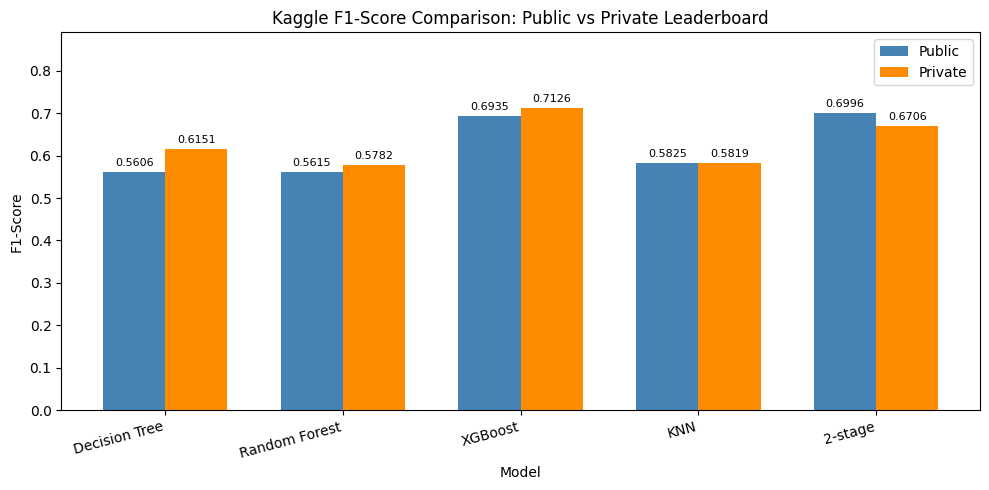

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

model    = ['Decision Tree', 'Random Forest', 'XGBoost', 'KNN',   "2-Stage"]
private_scores = [0.61514,          0.57822,         0.71255,   0.58186, 0.67061]
public_scores  = [0.56062,          0.56152,         0.69355,   0.58245, 0.69955]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars_pub  = ax.bar(x - width/2, public_scores,  width, label='Public',  color='steelblue')
bars_priv = ax.bar(x + width/2, private_scores, width, label='Private', color='darkorange')

ax.set_xlabel('Model')
ax.set_ylabel('F1-Score')
ax.set_title('Kaggle F1-Score Comparison: Public vs Private Leaderboard')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=15, ha='right')
ax.legend()
ax.set_ylim(0, max(max(public_scores), max(private_scores)) * 1.25)

for bar in bars_pub:
    ax.annotate(f'{bar.get_height():.4f}',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)
for bar in bars_priv:
    ax.annotate(f'{bar.get_height():.4f}',
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()